# 06 — Anomaly-Aware Energy Prediction

## Overview

This notebook trains and evaluates five energy prediction models on UAV flight data,
investigating whether augmenting base battery features with a CNN-LSTM-AE anomaly score
improves prediction accuracy on abnormal flights.

### What this notebook does
- Loads and configures all libraries, paths, and hyperparameters
- Defines feature sets (Base 13 features vs Base 13 + CNN anomaly score)
- Trains tree models: XGBoost, Random Forest, Linear Regression
- Trains sequence models: LSTM and BiLSTM (V1, confirmed as final)
- Evaluates energy prediction MAE on normal and abnormal test flights
- Estimates Remaining Flight Time (RFT) and analyses overprediction safety
- Runs SHAP (XGBoost) and permutation importance (LSTM, BiLSTM) for feature analysis
- Performs Wilcoxon significance tests for LSTM and BiLSTM
- Builds abnormal flight taxonomy from unscaled fleet data

### Key finding
The CNN anomaly score significantly improves energy prediction on abnormal flights
for both LSTM (Δ +0.233 Wh, p < 0.0001) and BiLSTM (Δ +0.243 Wh, p < 0.0001),
while introducing a small, statistically significant degradation on normal flights.


## 1. Libraries and Configuration

In [1]:

import os
import gc
import warnings
import psutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

import torch
import torch.nn as nn
from pathlib import Path
from scipy.stats import wilcoxon
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

# ── Paths ──────────────────────────────────────────────────────
BASE_DIR      = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
FOLDER_VER    = "v3_voltage_random10_issue_flight-removed"
FILE_VER      = "v4_voltage_random10_cleaned"
DATA_DIR      = BASE_DIR / f"model_ready_no_dr_{FOLDER_VER}"
CNN_SCORE_DIR = BASE_DIR / "model_outputs" / f"cnn_lstm_ae_anomaly_score_{FOLDER_VER}"
OUTPUT_DIR    = BASE_DIR / "model_outputs" / "06_anomaly_aware_energy"
PLOT_DIR      = OUTPUT_DIR / "plots"
RFT_PLOT_DIR  = PLOT_DIR / "rft_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
RFT_PLOT_DIR.mkdir(parents=True, exist_ok=True)


PRIMARY_SPLIT = "split_05_seed_55"
TARGET        = "target_energy_next_60s_wh"
FAULT_FLIGHT  = "f53dabf1-a0fb-433e-8ba8-f09c569db684"  # excluded sensor fault

device = torch.device(
    "mps"  if torch.backends.mps.is_available() else
    "cuda" if torch.cuda.is_available()          else
    "cpu"
)
print(f"Device  : {device}")
print(f"RAM free: {psutil.virtual_memory().available/1e9:.1f} GB")

# ── Reproducibility — fix all RNG sources before any model init ──
import random
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(RANDOM_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False
print(f"Random seed fixed: {RANDOM_SEED}  Device: {device}")


Device  : mps
RAM free: 2.9 GB
Random seed fixed: 42  Device: mps


## 2. Feature Sets

In [2]:
# ── Base 13 features used by all models
BASE_FEATURES = [
    "battery_status__cell_count",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__discharged_mah",
    "battery_status__remaining",
    "battery_status__scale",
    "battery_status__voltage_filtered_v",
    "battery_status__voltage_v",
    "cumulative_energy_wh",
    "power_w",
    "time_s",
    "voltage_per_cell",
    "voltage_filtered_per_cell",
]

# ── Two feature sets: base vs anomaly-augmented
# Note: anomaly_score_cnn is only available on the test set.
# Train and val receive a zero placeholder (see Section 3).
# This mirrors a real deployment scenario where the anomaly
# detector runs live at inference time only.
FEATURE_SETS = {
    "Base_13":           BASE_FEATURES,
    "Base_13+CNN_Score": BASE_FEATURES + ["anomaly_score_cnn"],
}

print("Feature sets defined:")
for name, feats in FEATURE_SETS.items():
    print(f"  {name}: {len(feats)} features")


Feature sets defined:
  Base_13: 13 features
  Base_13+CNN_Score: 14 features


## 3. Load Data

Loads scaled train/val/test parquets from the primary split.
CNN anomaly scores (only available for the test set) are merged in.
Train and val receive a zero placeholder for the anomaly score column —
this is a deliberate design choice, not a limitation:
the anomaly detector operates at inference time only, matching real deployment.


In [3]:
split_dir = DATA_DIR / PRIMARY_SPLIT
cnn_dir   = CNN_SCORE_DIR / PRIMARY_SPLIT

train_df = pd.read_parquet(
    split_dir / f"train_no_dr_scaled_{FILE_VER}_{PRIMARY_SPLIT}.parquet"
)
val_df = pd.read_parquet(
    split_dir / f"val_no_dr_scaled_{FILE_VER}_{PRIMARY_SPLIT}.parquet"
)
test_df = pd.read_parquet(
    split_dir / f"test_no_dr_scaled_{FILE_VER}_{PRIMARY_SPLIT}.parquet"
)

# ── Merge CNN anomaly scores into test set ────────────────────
cnn_test = pd.read_parquet(
    cnn_dir / f"test_cnn_lstm_ae_scored_{PRIMARY_SPLIT}.parquet",
    columns=["log_id", "time_s", "anomaly_score_cnn", "anomaly_flag_cnn"]
)

test_df  = test_df.sort_values(["log_id", "time_s"]).reset_index(drop=True)
cnn_test = cnn_test.sort_values(["log_id", "time_s"]).reset_index(drop=True)

if len(test_df) == len(cnn_test):
    test_df["anomaly_score_cnn"] = cnn_test["anomaly_score_cnn"].values.astype(np.float32)
    test_df["anomaly_flag_cnn"]  = cnn_test["anomaly_flag_cnn"].values.astype(np.int8)
    print("CNN scores merged into test set ✓")
else:
    print(f"Row mismatch: base={len(test_df)} cnn={len(cnn_test)}")

# ── Zero placeholder for train and val ────────────────────────
for df in [train_df, val_df]:
    df["anomaly_score_cnn"] = np.float32(0.0)
    df["anomaly_flag_cnn"]  = np.int8(0)

# ── Downcast float64 to float32 to reduce memory ─────────────
for df in [train_df, val_df, test_df]:
    for col in df.select_dtypes("float64").columns:
        df[col] = df[col].astype(np.float32)

del cnn_test
gc.collect()

print(f"Train : {train_df.shape}  Val : {val_df.shape}  Test : {test_df.shape}")
print(f"RAM free: {psutil.virtual_memory().available/1e9:.1f} GB")
print(f"Target range: {train_df[TARGET].min():.4f} – {train_df[TARGET].max():.4f} Wh")


CNN scores merged into test set ✓
Train : (658626, 19)  Val : (145797, 19)  Test : (162502, 19)
RAM free: 2.9 GB
Target range: 0.0000 – 27.5020 Wh


## 4. Load Unscaled Reference Data

Loads interpolated (unscaled) parquets for real-time and battery-remaining values.
Used for RFT calculations and the abnormal flight taxonomy.
`raw_test` covers the 6 test flights used in early RFT plots.
`raw_test_full` covers all 26 test flights for full RFT evaluation.


In [4]:
INTERP_DIR = BASE_DIR / "model_ready_no_dr_v3_voltage_random10_interpolated" / PRIMARY_SPLIT

# Full 26-flight unscaled test set (used for RFT)
raw_test_full = pd.read_parquet(
    INTERP_DIR /
    f"test_no_dr_interpolated_v3_voltage_random10_interpolated_{PRIMARY_SPLIT}.parquet"
)

# Cleaned 26-flight test set (matches scaled test_df exactly)
CORRECT_SPLIT_DIR = DATA_DIR / PRIMARY_SPLIT
raw_test = pd.read_parquet(
    CORRECT_SPLIT_DIR /
    f"test_no_dr_interpolated_v4_voltage_random10_cleaned_{PRIMARY_SPLIT}.parquet"
)

print(f"raw_test      : {raw_test.shape},      flights={raw_test['log_id'].nunique()}")
print(f"raw_test_full : {raw_test_full.shape}, flights={raw_test_full['log_id'].nunique()}")

# ── Verify all 26 test flights are covered ────────────────────
test_ids = set(test_df["log_id"].unique())
raw_ids  = set(raw_test["log_id"].unique())
missing  = test_ids - raw_ids
print(f"\nMissing flights in raw_test: {len(missing)}")
if len(missing) == 0:
    print("✓ All 26 flights covered")


raw_test      : (162502, 17),      flights=26
raw_test_full : (195237, 17), flights=26

Missing flights in raw_test: 0
✓ All 26 flights covered


## 5. Evaluation Helpers

In [5]:
def evaluate(y_true, y_pred, label="ALL"):
    """
    Compute standard regression metrics for a prediction array.

    Parameters
    ----------
    y_true : array-like  Ground truth energy values (Wh)
    y_pred : array-like  Predicted energy values (Wh)
    label  : str         Subset label for reporting (ALL / NORMAL / ABNORMAL)

    Returns
    -------
    dict with MAE, RMSE, R2, 95th-percentile error, underpredict %, row count
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    errors = y_true - y_pred
    return {
        "label":          label,
        "MAE_Wh":         round(mean_absolute_error(y_true, y_pred), 4),
        "RMSE_Wh":        round(np.sqrt(mean_squared_error(y_true, y_pred)), 4),
        "R2":             round(r2_score(y_true, y_pred), 4),
        "P95_error_Wh":   round(float(np.percentile(np.abs(errors), 95)), 4),
        "Underpredict_%": round((y_pred < y_true).mean() * 100, 2),
        "n_rows":         len(y_true),
    }


def full_eval(test_df, y_pred, feat_name, model_name):
    """
    Evaluate predictions across all flights, normal flights, and abnormal flights.

    Parameters
    ----------
    test_df    : pd.DataFrame  Test set with dataset_label and TARGET columns
    y_pred     : np.ndarray    Model predictions aligned to test_df rows
    feat_name  : str           Feature set name (e.g. 'Base_13+CNN_Score')
    model_name : str           Model name (e.g. 'XGBoost')

    Returns
    -------
    pd.DataFrame with one row per subset (ALL, NORMAL, ABNORMAL)
    """
    rows = [evaluate(test_df[TARGET], y_pred, "ALL")]
    for lbl in ["normal", "abnormal"]:
        mask = test_df["dataset_label"] == lbl
        if mask.sum() > 0:
            rows.append(evaluate(
                test_df.loc[mask, TARGET],
                y_pred[mask],
                lbl.upper()
            ))
    df = pd.DataFrame(rows)
    df["model"]       = model_name
    df["feature_set"] = feat_name
    return df


print("Evaluation helpers defined ✓")


Evaluation helpers defined ✓


## 6. Tree Model Training

Trains XGBoost, Random Forest, and Linear Regression on both feature sets.
All predictions are clipped to >= 0 (energy cannot be negative).
Results stored in `tree_preds` (dict of run_name → prediction array)
and `tree_df` (combined evaluation DataFrame).


In [6]:
tree_results = []
tree_preds   = {}

for feat_name, feat_cols in FEATURE_SETS.items():
    available = [f for f in feat_cols if f in train_df.columns]

    X_train = train_df[available].values
    y_train = train_df[TARGET].values
    X_test  = test_df[available].values

    print(f"\n{'='*55}")
    print(f"Feature set: {feat_name} ({len(available)} features)")
    print(f"{'='*55}")

    # ── XGBoost ──────────────────────────────────────────────
    print("Training XGBoost...")
    xgb = XGBRegressor(
        n_estimators=200, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, verbosity=0, tree_method="hist"
    )
    xgb.fit(X_train, y_train)
    y_pred = np.clip(xgb.predict(X_test), 0, None)
    result = full_eval(test_df, y_pred, feat_name, "XGBoost")
    tree_results.append(result)
    tree_preds[f"XGBoost_{feat_name}"] = y_pred
    print(f"  ABNORMAL MAE: {float(result[result['label']=='ABNORMAL']['MAE_Wh']):.4f} Wh")
    del xgb; gc.collect()

    # ── Random Forest ─────────────────────────────────────────
    print("Training Random Forest...")
    rf = RandomForestRegressor(
        n_estimators=100, max_depth=10, random_state=42, n_jobs=-1
    )
    rf.fit(X_train, y_train)
    y_pred = np.clip(rf.predict(X_test), 0, None)
    result = full_eval(test_df, y_pred, feat_name, "RandomForest")
    tree_results.append(result)
    tree_preds[f"RandomForest_{feat_name}"] = y_pred
    print(f"  ABNORMAL MAE: {float(result[result['label']=='ABNORMAL']['MAE_Wh']):.4f} Wh")
    del rf; gc.collect()

    # ── Linear Regression ─────────────────────────────────────
    print("Training Linear Regression...")
    lr = LinearRegression()
    lr.fit(X_train, y_train)
    y_pred = np.clip(lr.predict(X_test), 0, None)
    result = full_eval(test_df, y_pred, feat_name, "LinearRegression")
    tree_results.append(result)
    tree_preds[f"LinearRegression_{feat_name}"] = y_pred
    print(f"  ABNORMAL MAE: {float(result[result['label']=='ABNORMAL']['MAE_Wh']):.4f} Wh")
    del lr; gc.collect()

    del X_train, y_train, X_test; gc.collect()

tree_df = pd.concat(tree_results, ignore_index=True)
print("\n✓ Tree models done.")



Feature set: Base_13 (13 features)
Training XGBoost...
  ABNORMAL MAE: 2.1476 Wh
Training Random Forest...
  ABNORMAL MAE: 2.4533 Wh
Training Linear Regression...
  ABNORMAL MAE: 1.3217 Wh

Feature set: Base_13+CNN_Score (14 features)
Training XGBoost...
  ABNORMAL MAE: 2.2011 Wh
Training Random Forest...
  ABNORMAL MAE: 2.4227 Wh
Training Linear Regression...
  ABNORMAL MAE: 1.3217 Wh

✓ Tree models done.


## 7. Sequence Model Definitions (LSTM and BiLSTM)

V1 architecture — confirmed as final results.

**Reproducibility:** `RANDOM_SEED = 42` is set globally in Section 1.
Seeds are re-applied before every model init and DataLoader shuffle.
Checkpoints saved to `checkpoints_seed42/` — reruns cannot overwrite them.
- `FastFlightDataset`: pre-builds all sliding-window sequences at init time
- `LSTMRegressor`: single-layer LSTM, hidden=64
- `BiLSTMRegressor`: single-layer bidirectional LSTM, hidden=64
- `train_seq_model`: Huber loss, Adam optimiser, ReduceLROnPlateau, early stopping
- `predict_seq`: batched inference per flight

### Note on V2 retraining attempt
Larger models (hidden=128, 2 layers, seq_len=60) were tested but produced
higher MAE. Root cause: 92.1% of training sequences are idle-phase rows
(target < 0.05 Wh). Larger models overfit this dominant pattern.
V1 results are retained as final. See Section 12 for full documentation.


In [7]:
# ── Hyperparameters ──────────────────────────────────────────
SEQ_LEN    = 30    # 3 seconds of history at 10 Hz
BATCH_SIZE = 512
EPOCHS     = 30
PATIENCE   = 5


class FastFlightDataset(torch.utils.data.Dataset):
    """
    PyTorch Dataset that pre-builds all sliding-window sequences at init time.

    Iterates over each flight, extracts (seq_len, n_features) windows
    and corresponding targets, stacks them into tensors.
    Flights shorter than seq_len are skipped.

    Parameters
    ----------
    df       : pd.DataFrame  Scaled data with log_id, time_s, feat_cols, target
    feat_cols: list[str]     Feature column names
    target   : str           Target column name
    seq_len  : int           Sliding window length (rows)
    """
    def __init__(self, df, feat_cols, target, seq_len):
        seqs, tgts = [], []
        for _, grp in (df.sort_values(["log_id", "time_s"])
                         .groupby("log_id", sort=False)):
            X = grp[feat_cols].to_numpy(dtype=np.float32)
            y = grp[target].to_numpy(dtype=np.float32)
            n = len(X)
            if n <= seq_len:
                continue
            for i in range(seq_len, n):
                seqs.append(X[i - seq_len:i])
                tgts.append(y[i])
        self.X = torch.from_numpy(np.array(seqs, dtype=np.float32))
        self.y = torch.from_numpy(np.array(tgts, dtype=np.float32))
        print(f"  Dataset built: {len(self.y):,} sequences")

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.X[i], self.y[i]


class LSTMRegressor(nn.Module):
    """
    Single-layer unidirectional LSTM for energy prediction.

    Parameters
    ----------
    input_size : int   Number of input features
    hidden     : int   LSTM hidden units (default 64)
    num_layers : int   Number of stacked LSTM layers (default 1)
    dropout    : float Dropout rate (unused at num_layers=1)
    """
    def __init__(self, input_size, hidden=64, num_layers=1, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden, num_layers=num_layers,
            batch_first=True, dropout=0.0
        )
        self.head = nn.Sequential(
            nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


class BiLSTMRegressor(nn.Module):
    """
    Single-layer bidirectional LSTM for energy prediction.
    Output dimension is hidden*2 due to concatenated forward/backward states.

    Parameters
    ----------
    input_size : int   Number of input features
    hidden     : int   Per-direction LSTM hidden units (default 64)
    num_layers : int   Number of stacked LSTM layers (default 1)
    dropout    : float Dropout rate (unused at num_layers=1)
    """
    def __init__(self, input_size, hidden=64, num_layers=1, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden, num_layers=num_layers,
            batch_first=True, bidirectional=True, dropout=0.0
        )
        self.head = nn.Sequential(
            nn.Linear(hidden * 2, 32), nn.ReLU(), nn.Linear(32, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


def train_seq_model(model, train_ds, val_ds, model_name,
                    epochs=EPOCHS, patience=PATIENCE):
    """
    Train a sequence model with early stopping and checkpoint saving.

    Uses Huber loss (robust to outliers), Adam optimiser,
    and ReduceLROnPlateau scheduler. Best val-loss checkpoint is saved
    to OUTPUT_DIR and restored at the end of training.

    Parameters
    ----------
    model      : nn.Module           LSTM or BiLSTM model
    train_ds   : FastFlightDataset   Training sequences
    val_ds     : FastFlightDataset   Validation sequences
    model_name : str                 Used for checkpoint filename
    epochs     : int                 Maximum training epochs
    patience   : int                 Early stopping patience

    Returns
    -------
    model        : nn.Module   Best checkpoint loaded
    best_val     : float       Best validation loss achieved
    train_history: list[float] Per-epoch training loss
    val_history  : list[float] Per-epoch validation loss
    """
    criterion = nn.HuberLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, patience=2, factor=0.5
    )
    # Seeded generator so shuffle order is identical every run
    _g = torch.Generator()
    _g.manual_seed(RANDOM_SEED)
    train_loader = torch.utils.data.DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=0, generator=_g
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds, batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=0
    )
    best_val = np.inf
    pat_ctr  = 0
    # Versioned checkpoint dir — reruns never overwrite final results
    ckpt_dir = OUTPUT_DIR / f"checkpoints_seed{RANDOM_SEED}"
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    ckpt     = ckpt_dir / f"ckpt_{model_name}.pt"
    trh, vlh = [], []

    for epoch in range(1, epochs + 1):
        model.train()
        tl = []
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            tl.append(loss.item())
        t_loss = float(np.mean(tl))
        trh.append(t_loss)

        model.eval()
        vl = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                vl.append(criterion(model(xb), yb).item())
        v_loss = float(np.mean(vl))
        vlh.append(v_loss)
        scheduler.step(v_loss)
        print(f"  Ep {epoch:02d} | Train:{t_loss:.5f} Val:{v_loss:.5f}")

        if v_loss < best_val - 1e-5:
            best_val = v_loss
            pat_ctr  = 0
            torch.save(model.state_dict(), ckpt)
        else:
            pat_ctr += 1
            if pat_ctr >= patience:
                print(f"  Early stop at epoch {epoch}. Best val: {best_val:.5f}")
                break

    model.load_state_dict(
        torch.load(ckpt, map_location=device, weights_only=True)
    )
    model.eval()
    return model, best_val, trh, vlh


def predict_seq(model, df, feat_cols, target, seq_len, batch_size=512):
    """
    Run batched inference on a sequence model for all flights in df.

    Builds sliding windows per flight, runs them through the model in batches,
    and returns a flat prediction DataFrame. The first seq_len rows of each
    flight have no prediction (used as input context only).

    Parameters
    ----------
    model     : nn.Module    Trained LSTM or BiLSTM
    df        : pd.DataFrame Scaled data with log_id, time_s, feat_cols, target
    feat_cols : list[str]    Feature column names
    target    : str          Target column name
    seq_len   : int          Sliding window length
    batch_size: int          Inference batch size

    Returns
    -------
    pd.DataFrame with columns: log_id, dataset_label, time_s, y_true, y_pred
    """
    model.eval()
    records = []
    for lid, grp in df.sort_values(["log_id", "time_s"]).groupby("log_id"):
        X   = grp[feat_cols].to_numpy(dtype=np.float32)
        y   = grp[target].to_numpy(dtype=np.float32)
        t   = grp["time_s"].to_numpy()
        lbl = grp["dataset_label"].iloc[0]
        n   = len(X)
        if n <= seq_len:
            continue
        seqs = np.stack([X[i - seq_len:i] for i in range(seq_len, n)])
        seqs_t = torch.tensor(seqs, dtype=torch.float32)
        preds  = []
        with torch.no_grad():
            for batch in torch.split(seqs_t, batch_size):
                preds.extend(model(batch.to(device)).cpu().numpy().tolist())
        for p, yt, ts in zip(preds, y[seq_len:], t[seq_len:]):
            records.append({
                "log_id": lid, "dataset_label": lbl,
                "time_s": ts, "y_true": float(yt), "y_pred": float(p),
            })
    return pd.DataFrame(records)


print("Sequence model classes and helpers defined ✓")


Sequence model classes and helpers defined ✓


## 8. Sequence Model Training (LSTM and BiLSTM — V1 Final)

Trains LSTM and BiLSTM on both feature sets (Base_13 and Base_13+CNN_Score).
Results stored in `seq_preds` (dict of run_name → prediction DataFrame)
and `seq_df` (combined evaluation DataFrame).

These are the final V1 results used throughout the thesis.


In [8]:
ARCH_CLASSES = {
    "LSTM":   LSTMRegressor,
    "BiLSTM": BiLSTMRegressor,
}

seq_results = []
seq_preds   = {}

for feat_name, feat_cols in FEATURE_SETS.items():
    available = [f for f in feat_cols if f in train_df.columns]

    print(f"\nBuilding datasets for {feat_name}...")
    train_ds = FastFlightDataset(train_df, available, TARGET, SEQ_LEN)
    val_ds   = FastFlightDataset(val_df,   available, TARGET, SEQ_LEN)

    for arch_name, ModelClass in ARCH_CLASSES.items():
        run = f"{arch_name}_{feat_name}"
        print(f"\n{'='*55}")
        print(f"TRAINING: {run} ({len(available)} features)")
        print(f"{'='*55}")

        # Re-seed before init so weights are identical regardless of loop order
        torch.manual_seed(RANDOM_SEED)
        np.random.seed(RANDOM_SEED)
        random.seed(RANDOM_SEED)
        model = ModelClass(input_size=len(available)).to(device)
        print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

        model, bv, trh, vlh = train_seq_model(model, train_ds, val_ds, run)
        pred_df = predict_seq(model, test_df, available, TARGET, SEQ_LEN)
        pred_df["y_pred"] = pred_df["y_pred"].clip(lower=0)

        for lbl in ["ALL", "normal", "abnormal"]:
            mask = pd.Series([True] * len(pred_df)) if lbl == "ALL"                    else pred_df["dataset_label"] == lbl
            lu   = "ALL" if lbl == "ALL" else lbl.upper()
            if mask.sum() == 0:
                continue
            row = evaluate(pred_df.loc[mask, "y_true"],
                           pred_df.loc[mask, "y_pred"], lu)
            row["model"]       = arch_name
            row["feature_set"] = feat_name
            seq_results.append(row)

        seq_preds[run] = pred_df
        abn = pred_df[pred_df["dataset_label"] == "abnormal"]
        if len(abn) > 0:
            print(f"  ABNORMAL MAE: "
                  f"{mean_absolute_error(abn['y_true'], abn['y_pred']):.4f} Wh")

        del model; gc.collect()
        if device.type == "mps":
            torch.mps.empty_cache()

    del train_ds, val_ds; gc.collect()

seq_df = pd.DataFrame(seq_results)
print("\n✓ Sequence models done.")



Building datasets for Base_13...
  Dataset built: 655,146 sequences
  Dataset built: 145,047 sequences

TRAINING: LSTM_Base_13 (13 features)
Parameters: 22,337
  Ep 01 | Train:0.16715 Val:0.21454
  Ep 02 | Train:0.08231 Val:0.23983
  Ep 03 | Train:0.07451 Val:0.25034
  Ep 04 | Train:0.06817 Val:0.28259
  Ep 05 | Train:0.05553 Val:0.29875
  Ep 06 | Train:0.05013 Val:0.31698
  Early stop at epoch 6. Best val: 0.21454
  ABNORMAL MAE: 1.2031 Wh

TRAINING: BiLSTM_Base_13 (13 features)
Parameters: 44,609
  Ep 01 | Train:0.16416 Val:0.25066
  Ep 02 | Train:0.08281 Val:0.24406
  Ep 03 | Train:0.07257 Val:0.22168
  Ep 04 | Train:0.06558 Val:0.25529
  Ep 05 | Train:0.06257 Val:0.22339
  Ep 06 | Train:0.05580 Val:0.27105
  Ep 07 | Train:0.04130 Val:0.27434
  Ep 08 | Train:0.03447 Val:0.27534
  Early stop at epoch 8. Best val: 0.22168
  ABNORMAL MAE: 1.1053 Wh

Building datasets for Base_13+CNN_Score...
  Dataset built: 655,146 sequences
  Dataset built: 145,047 sequences

TRAINING: LSTM_Base_13+

## 9. Master Results Table

In [9]:
# ── Combine tree and sequence results ────────────────────────
all_results = pd.concat([tree_df, seq_df], ignore_index=True)
all_results.to_csv(OUTPUT_DIR / "master_results.csv", index=False)

print("=" * 70)
print("MASTER COMPARISON — ABNORMAL FLIGHTS")
print("=" * 70)

abn = all_results[all_results["label"] == "ABNORMAL"].copy()
abn = abn.sort_values("MAE_Wh").reset_index(drop=True)
abn.index += 1
display(abn[["model", "feature_set", "MAE_Wh", "RMSE_Wh",
             "R2", "P95_error_Wh", "Underpredict_%"]])

print("\n" + "=" * 70)
print("KEY FINDING: Does CNN anomaly score improve ABNORMAL MAE?")
print("=" * 70)
for model_name in ["XGBoost", "RandomForest", "LSTM", "BiLSTM"]:
    sub = abn[abn["model"] == model_name]
    if len(sub) == 0:
        continue
    base = float(sub[sub["feature_set"] == "Base_13"]["MAE_Wh"])
    cnn  = float(sub[sub["feature_set"] == "Base_13+CNN_Score"]["MAE_Wh"])
    diff = base - cnn
    sign = "▼ IMPROVES" if diff > 0.001 else ("▲ WORSENS" if diff < -0.001 else "≈ NO CHANGE")
    print(f"  {model_name:<16} Base:{base:.4f}  +CNN:{cnn:.4f}  Δ={diff:+.4f}  {sign}")


MASTER COMPARISON — ABNORMAL FLIGHTS


,model,feature_set,MAE_Wh,RMSE_Wh,R2,P95_error_Wh,Underpredict_%
1,BiLSTM,Base_13+CNN_Score,0.9106,1.4842,0.7645,3.3360,46.44
2,BiLSTM,Base_13,1.1053,1.8761,0.6236,4.3966,43.75
3,LSTM,Base_13,1.2031,1.9609,0.5888,4.4858,35.23
4,LinearRegression,Base_13,1.3217,2.1475,0.5061,5.0160,36.62
5,LinearRegression,Base_13+CNN_Score,1.3217,2.1475,0.5061,5.0160,36.62
6,LSTM,Base_13+CNN_Score,1.5685,2.4887,0.3377,5.7117,34.41
7,XGBoost,Base_13,2.1476,4.0776,-0.7806,10.8180,28.92
8,XGBoost,Base_13+CNN_Score,2.2011,4.0830,-0.7854,10.8033,25.07
9,RandomForest,Base_13+CNN_Score,2.4227,5.2691,-1.9733,19.0198,30.08
10,RandomForest,Base_13,2.4533,5.2856,-1.9920,19.0406,30.11



KEY FINDING: Does CNN anomaly score improve ABNORMAL MAE?
  XGBoost          Base:2.1476  +CNN:2.2011  Δ=-0.0535  ▲ WORSENS
  RandomForest     Base:2.4533  +CNN:2.4227  Δ=+0.0306  ▼ IMPROVES
  LSTM             Base:1.2031  +CNN:1.5685  Δ=-0.3654  ▲ WORSENS
  BiLSTM           Base:1.1053  +CNN:0.9106  Δ=+0.1947  ▼ IMPROVES


## 10. Visualisation Helpers

Defines reusable plotting functions for:
- Energy prediction time series per flight
- Remaining flight time (RFT) time series per flight
- Helper to attach real (unscaled) elapsed time to prediction DataFrames


In [10]:
def attach_real_time(pred_df, raw_test_df):
    """
    Replace scaled time_s with real elapsed seconds by aligning row order per flight.

    Sequence models lose the first seq_len rows of each flight (used as context),
    so alignment is done by taking the last len(pred) rows of the raw reference.

    Parameters
    ----------
    pred_df     : pd.DataFrame  Prediction DataFrame with scaled time_s
    raw_test_df : pd.DataFrame  Unscaled reference with real time_s

    Returns
    -------
    pd.DataFrame with added column time_s_real (elapsed seconds from 0)
    """
    result_rows = []
    for lid, grp in pred_df.sort_values(["log_id", "time_s"]).groupby("log_id"):
        raw_grp = (raw_test_df[raw_test_df["log_id"] == lid]
                   .sort_values("time_s")
                   .reset_index(drop=True))
        grp = grp.reset_index(drop=True)
        n   = min(len(grp), len(raw_grp))
        grp = grp.iloc[:n].copy()
        grp["time_s_real"] = raw_grp["time_s"].values[:n]
        grp["time_s_real"] = grp["time_s_real"] - grp["time_s_real"].min()
        result_rows.append(grp)
    return pd.concat(result_rows, ignore_index=True)


def plot_energy_prediction(pred_df, raw_test_df, run_name,
                            flight_label="abnormal", save_dir=PLOT_DIR):
    """
    Time series plot for one flight showing actual vs predicted energy,
    empirical 90% prediction interval, and a residual panel.

    Picks the longest flight of the given label for display.

    Parameters
    ----------
    pred_df      : pd.DataFrame  Prediction DataFrame (y_true, y_pred)
    raw_test_df  : pd.DataFrame  Unscaled reference for real time axis
    run_name     : str           Model run name for title and filename
    flight_label : str           'normal' or 'abnormal'
    save_dir     : Path          Directory to save the plot
    """
    pred_real = attach_real_time(pred_df, raw_test_df)
    label_df  = pred_real[pred_real["dataset_label"] == flight_label]
    if len(label_df) == 0:
        return

    all_err = (label_df["y_true"] - label_df["y_pred"]).values
    pi_low  = float(np.percentile(all_err,  5))
    pi_high = float(np.percentile(all_err, 95))

    fid    = label_df.groupby("log_id").size().idxmax()
    flight = label_df[label_df["log_id"] == fid].sort_values("time_s_real")
    t, y_true, y_pred = (flight["time_s_real"].values,
                         flight["y_true"].values, flight["y_pred"].values)
    resid = y_true - y_pred

    fig, axes = plt.subplots(2, 1, figsize=(14, 8),
                              gridspec_kw={"height_ratios": [3, 1]})
    fig.suptitle(f"{run_name}  —  {flight_label.upper()} flight",
                 fontsize=11, fontweight="bold")

    ax = axes[0]
    ax.fill_between(t, y_pred + pi_low, y_pred + pi_high,
                    alpha=0.20, color="steelblue", label="90% prediction interval")
    ax.plot(t, y_true, color="black",     linewidth=1.5, label="Actual (Wh)")
    ax.plot(t, y_pred, color="steelblue", linewidth=1.5,
            linestyle="--", label="Predicted (Wh)")
    ax.set_ylabel("Energy next 60s (Wh)", fontsize=10)
    ax.set_title(f"Flight MAE: {mean_absolute_error(y_true, y_pred):.4f} Wh  |  "
                 f"PI width: {pi_high - pi_low:.4f} Wh", fontsize=9)
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

    axes[1].bar(t, resid, width=t[1] - t[0] if len(t) > 1 else 1,
                color=["#E53935" if r > 0 else "#1976D2" for r in resid], alpha=0.7)
    axes[1].axhline(0, color="black", linewidth=0.8)
    axes[1].set_xlabel("Elapsed flight time (s)", fontsize=10)
    axes[1].set_ylabel("Residual (Wh)", fontsize=10)
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    save_path = save_dir / f"energy_{run_name}_{flight_label}.png"
    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {save_path.name}")
    plt.close()


print("Visualisation helpers defined ✓")


Visualisation helpers defined ✓


## 11. Energy Prediction Plots

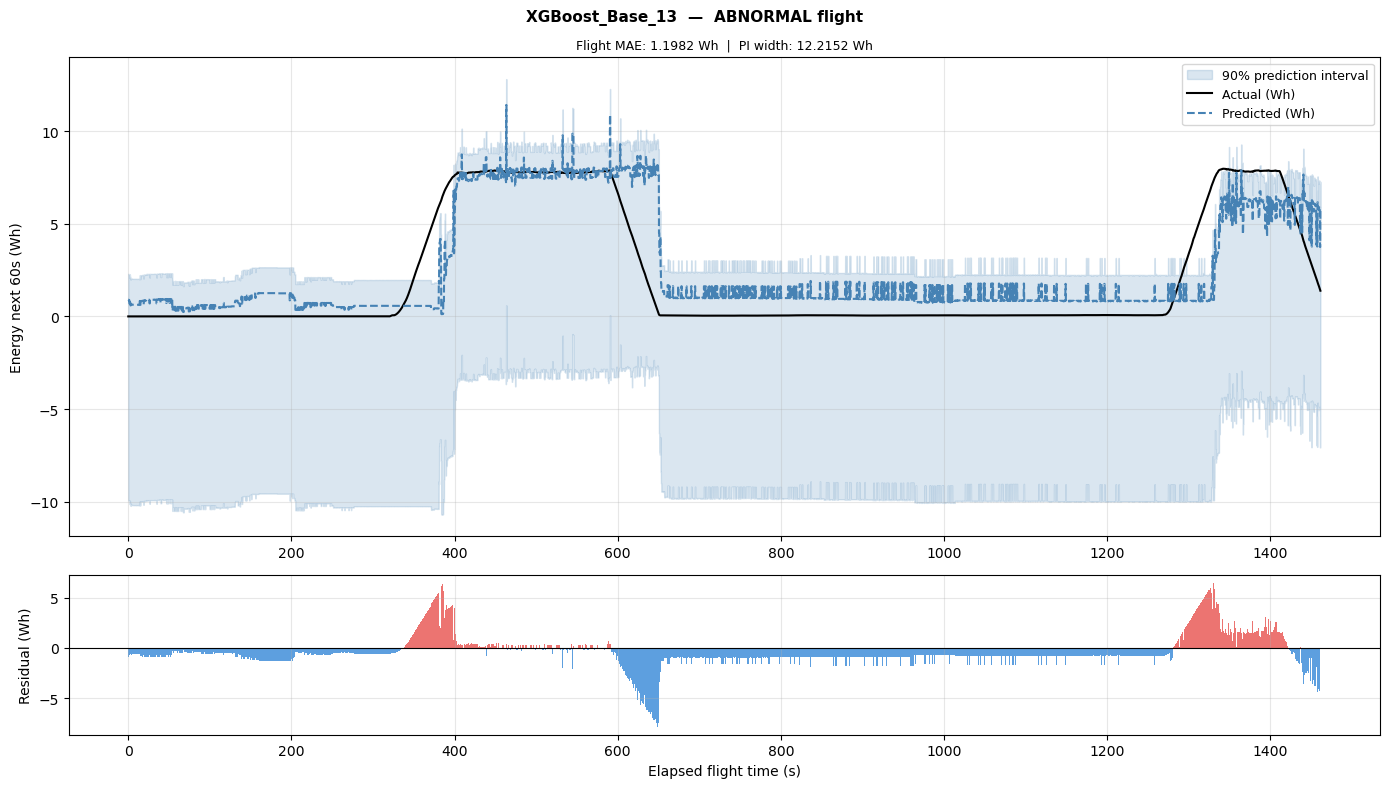

Saved: energy_XGBoost_Base_13_abnormal.png


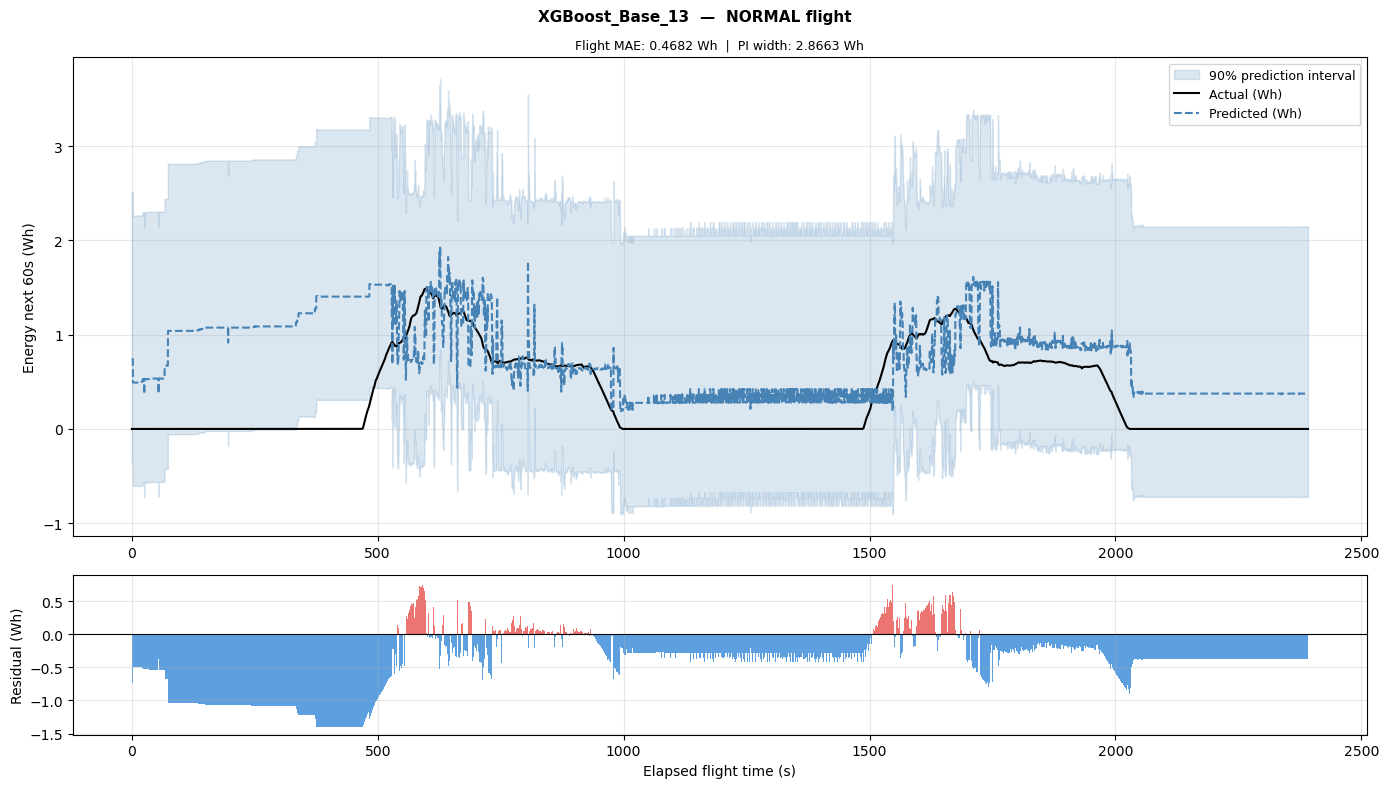

Saved: energy_XGBoost_Base_13_normal.png


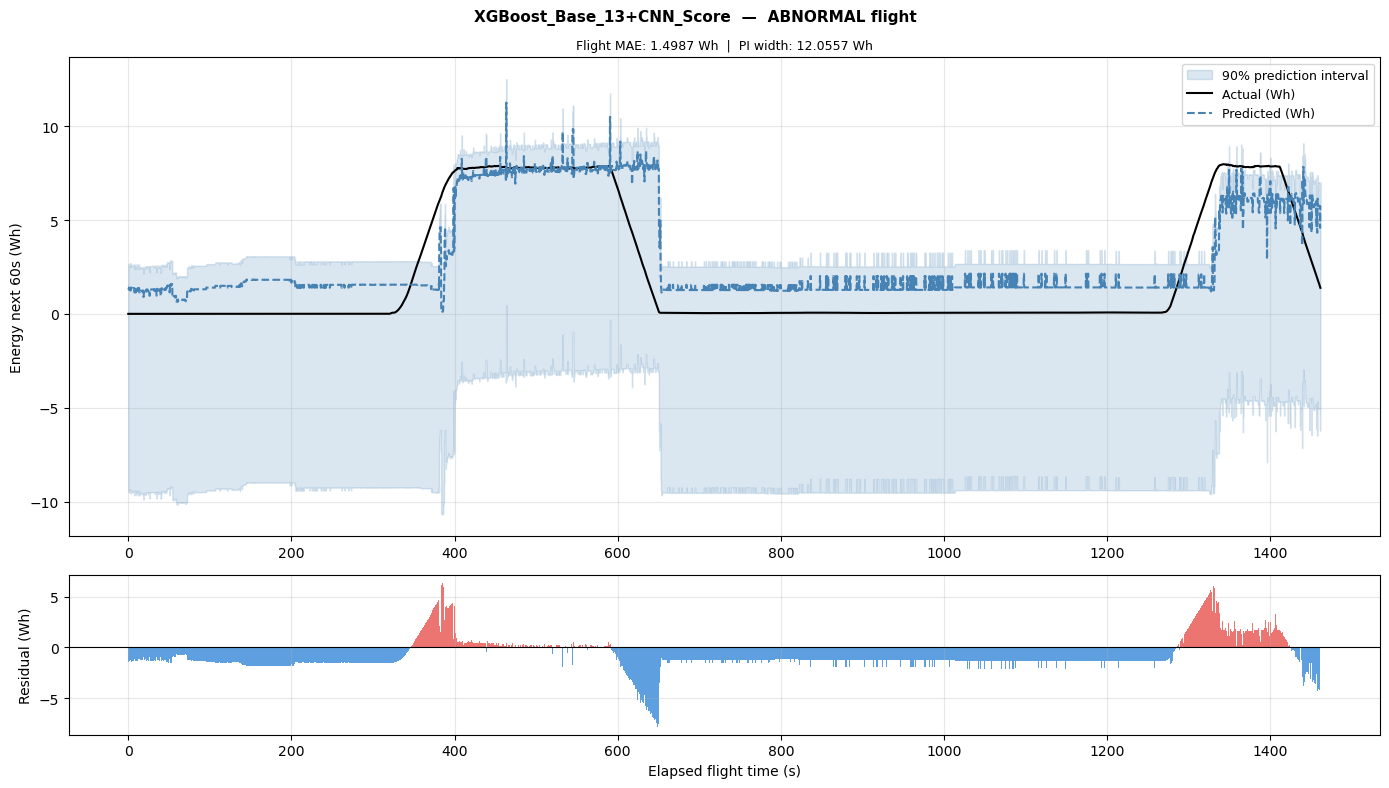

Saved: energy_XGBoost_Base_13+CNN_Score_abnormal.png


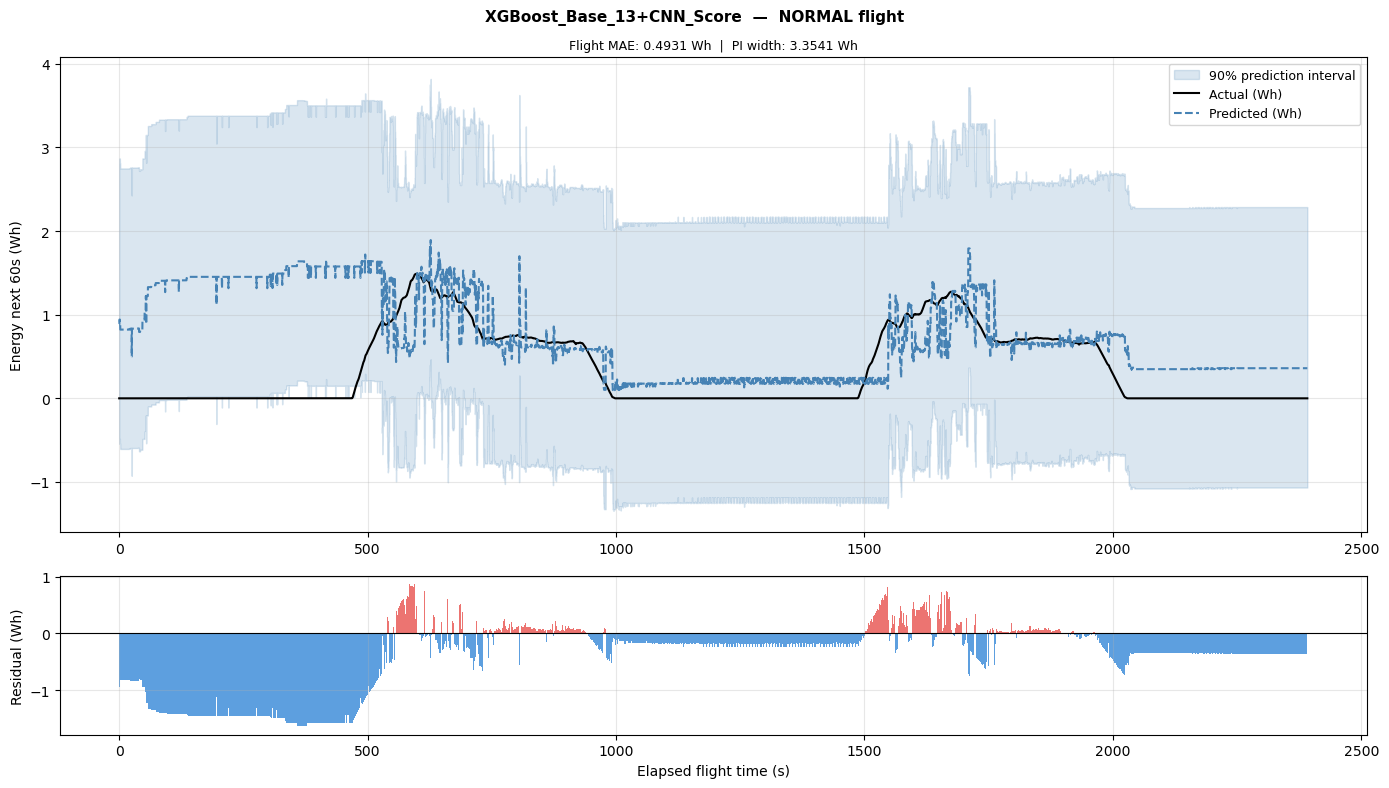

Saved: energy_XGBoost_Base_13+CNN_Score_normal.png


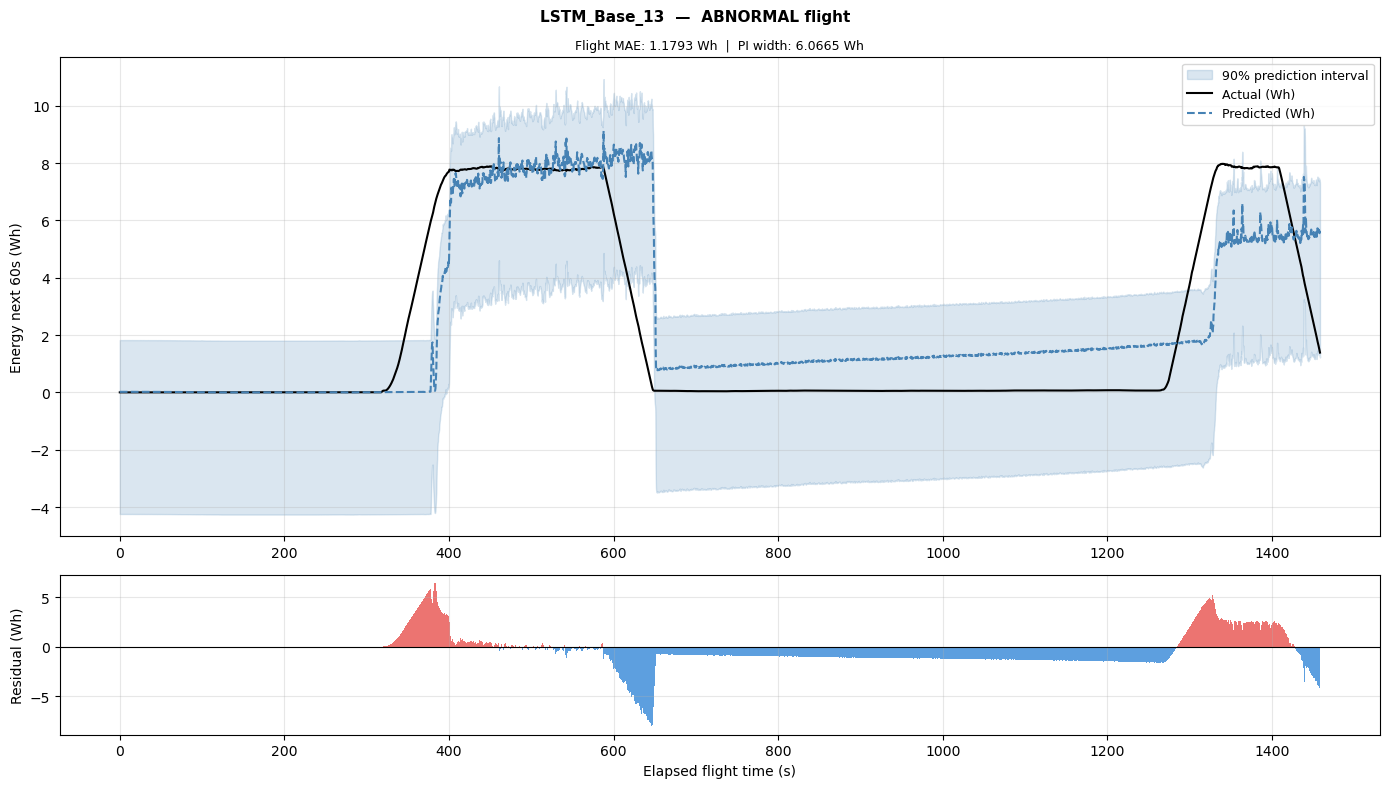

Saved: energy_LSTM_Base_13_abnormal.png


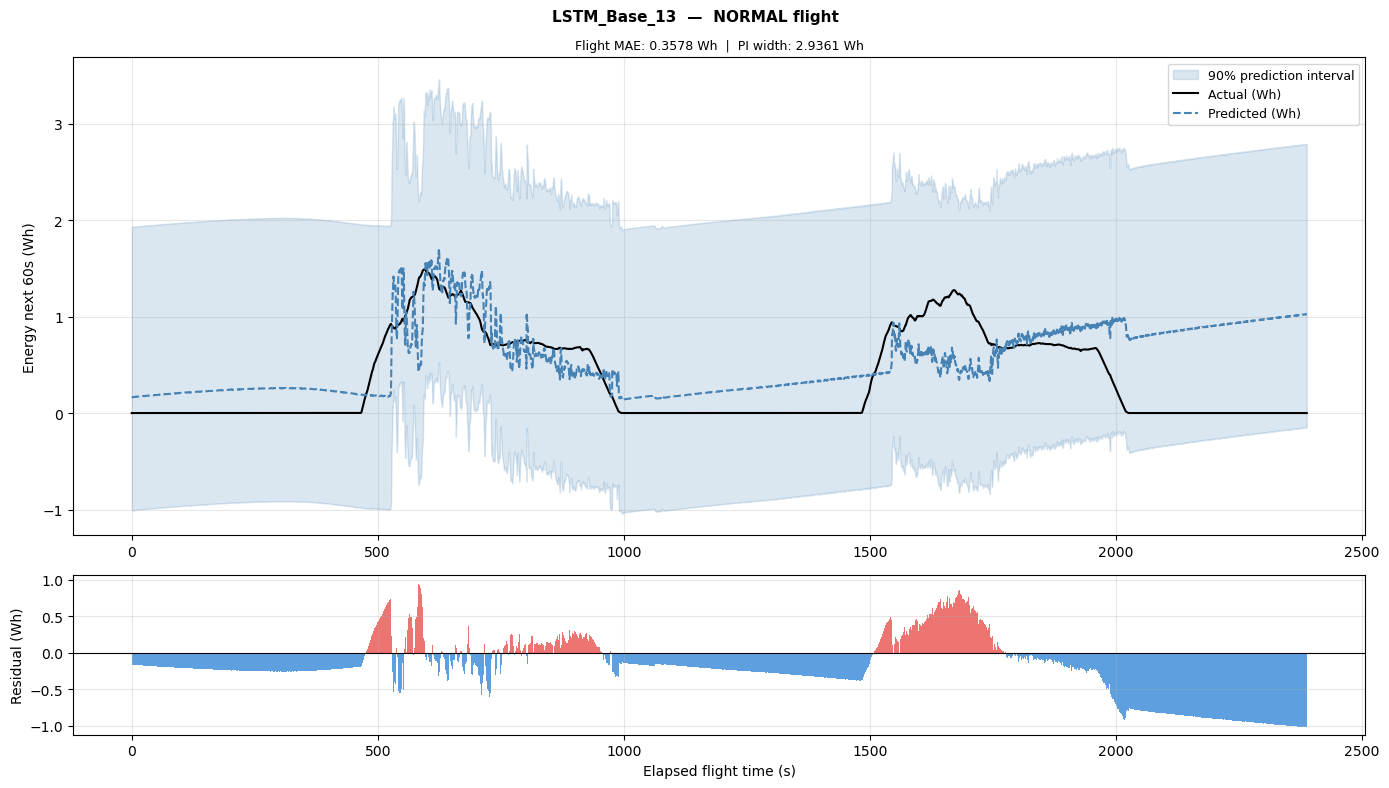

Saved: energy_LSTM_Base_13_normal.png


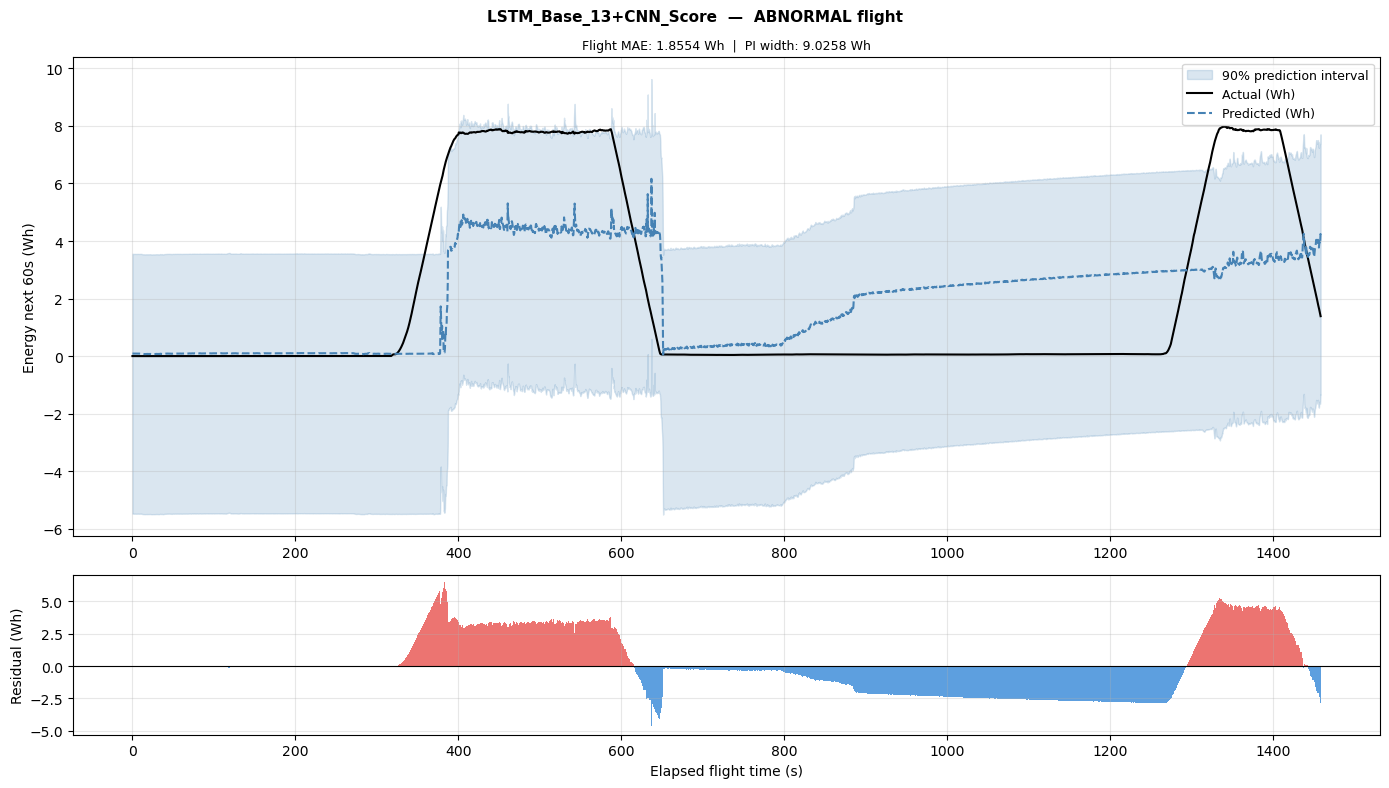

Saved: energy_LSTM_Base_13+CNN_Score_abnormal.png


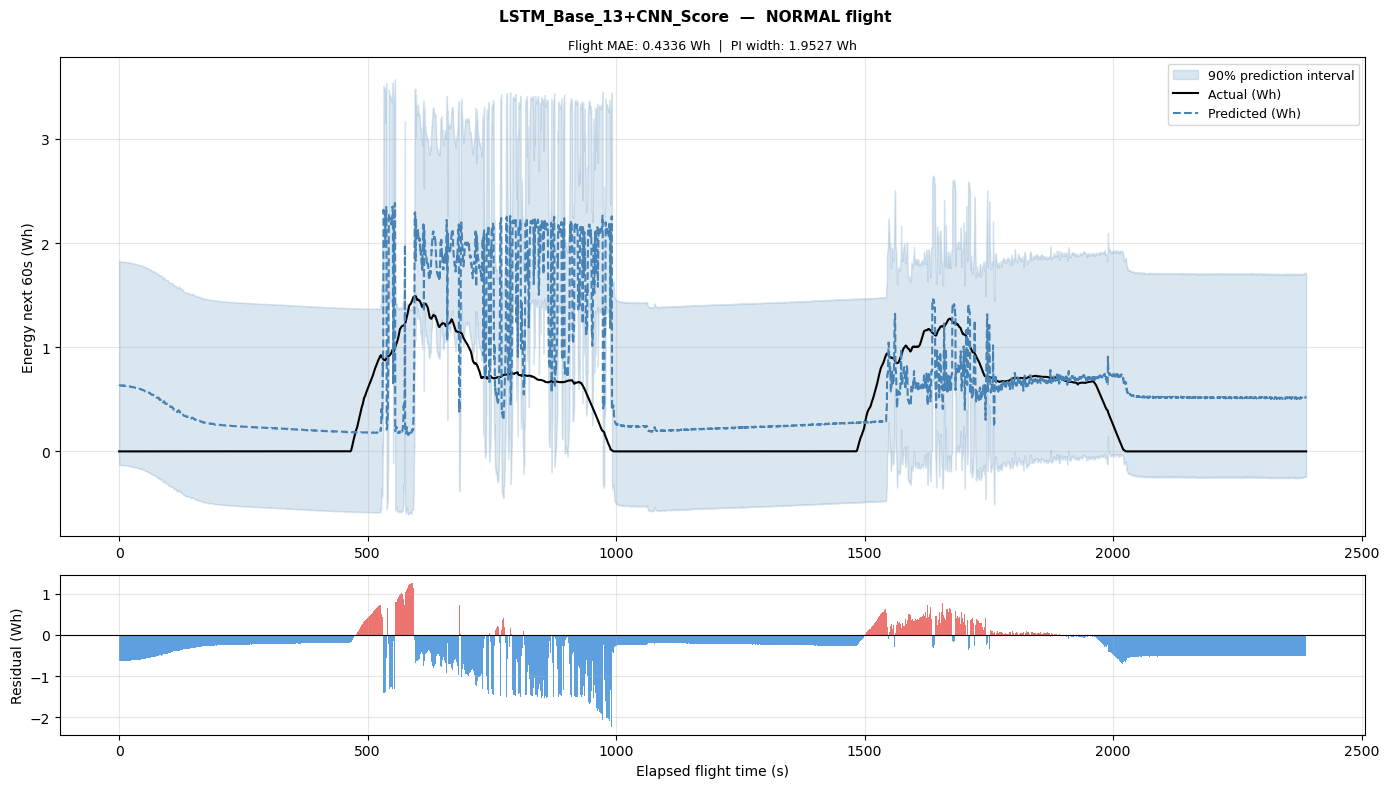

Saved: energy_LSTM_Base_13+CNN_Score_normal.png


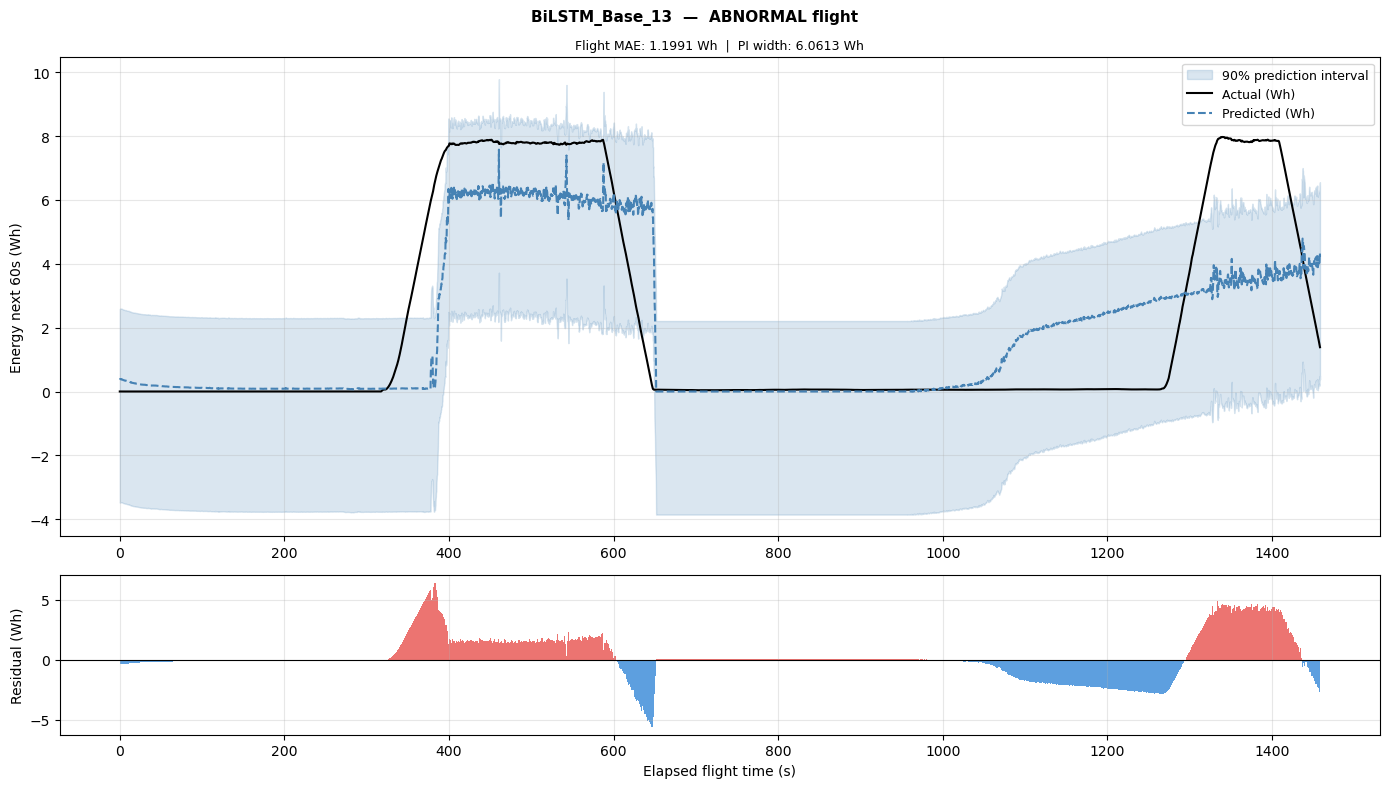

Saved: energy_BiLSTM_Base_13_abnormal.png


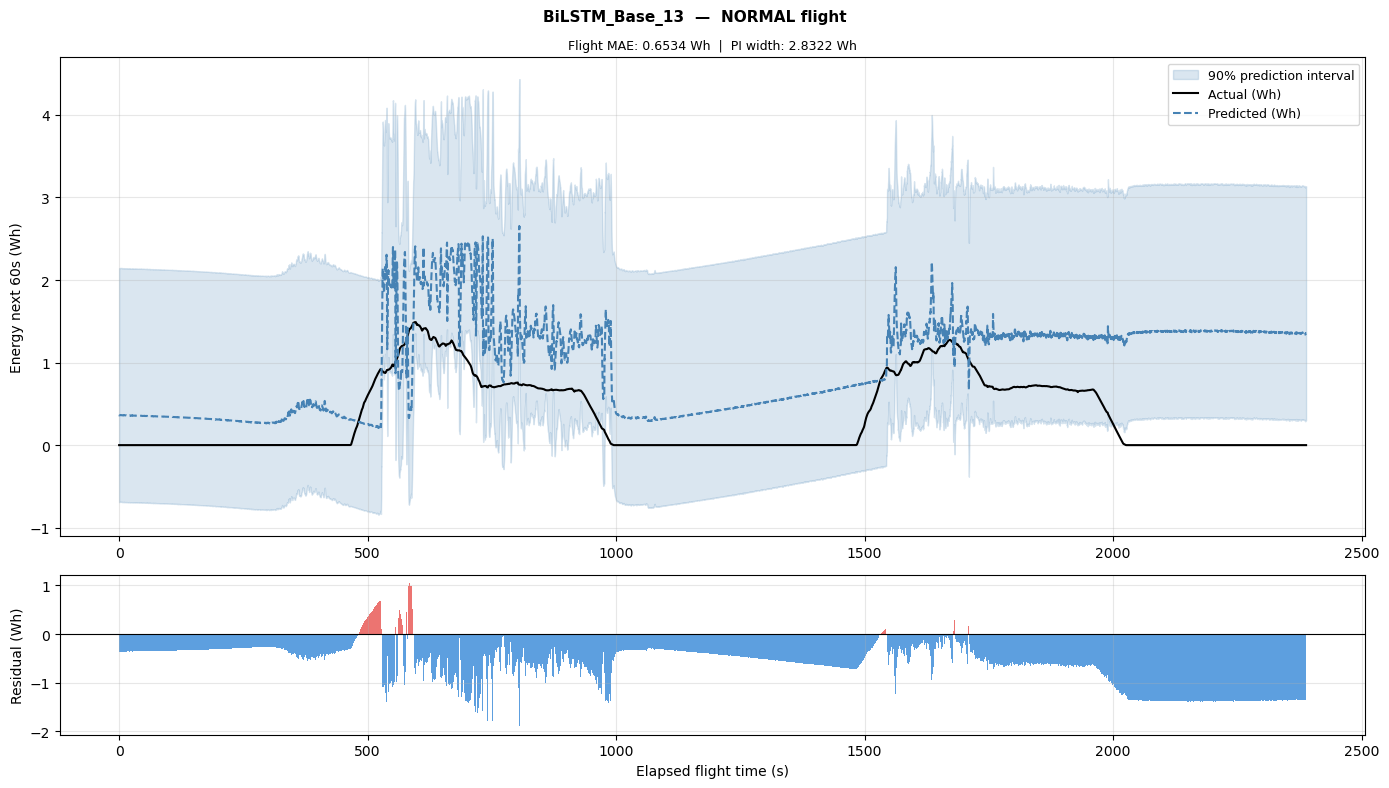

Saved: energy_BiLSTM_Base_13_normal.png


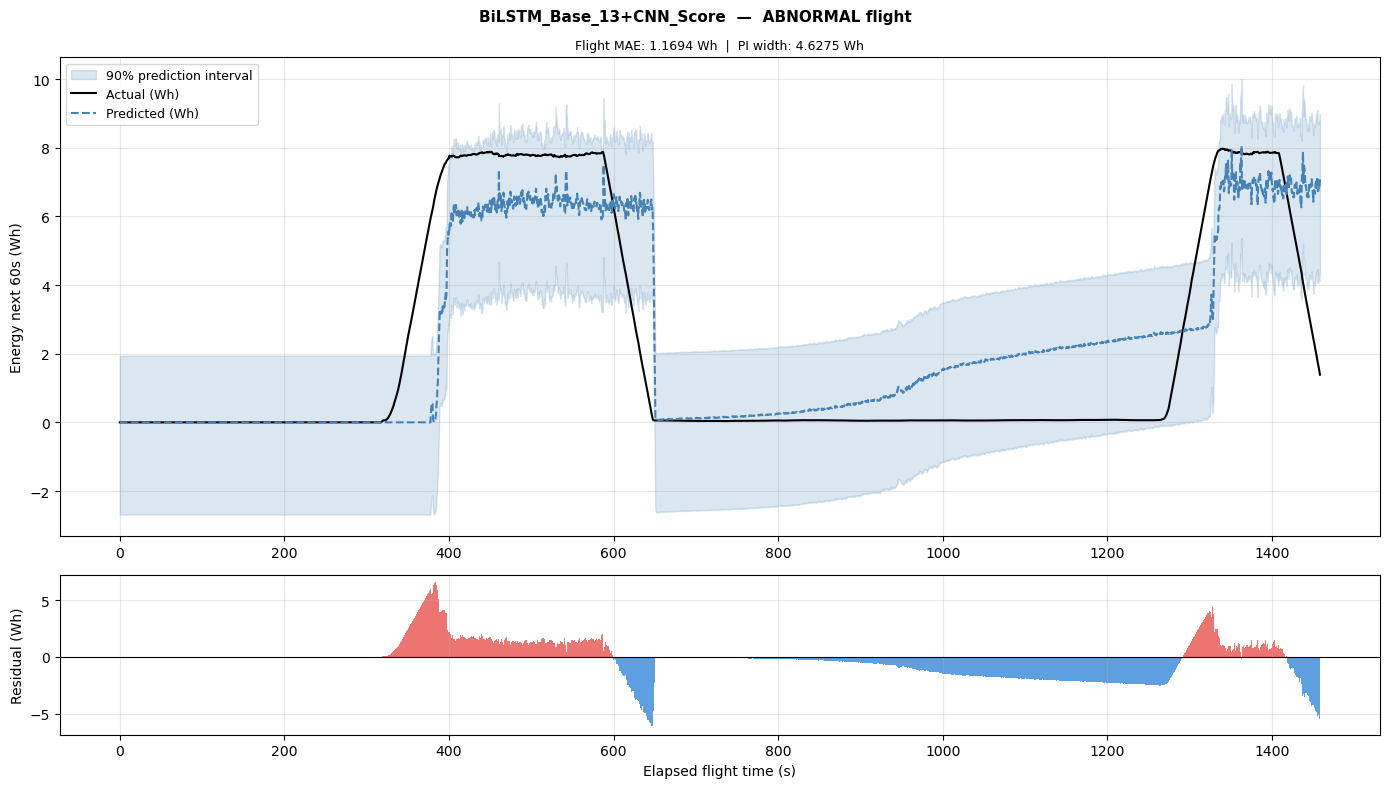

Saved: energy_BiLSTM_Base_13+CNN_Score_abnormal.png


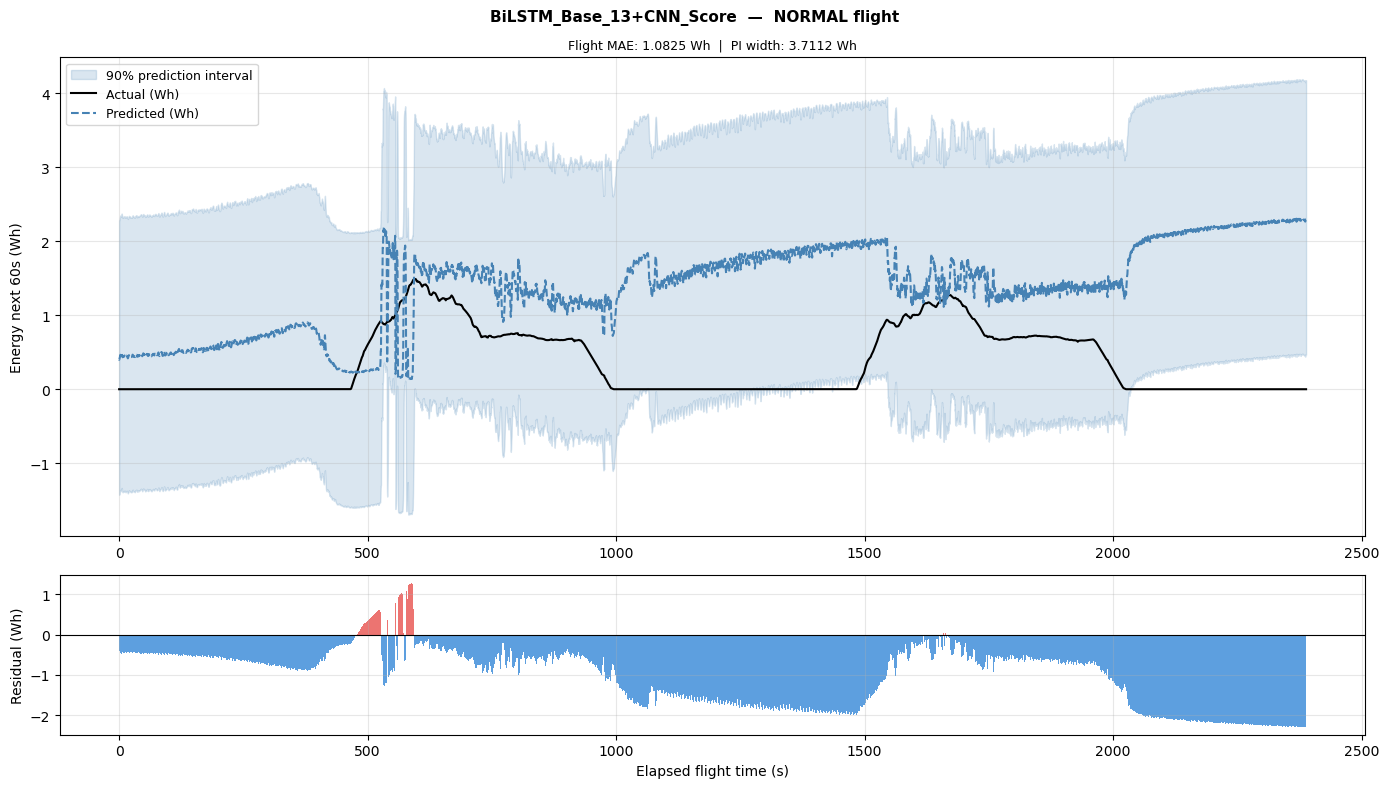

Saved: energy_BiLSTM_Base_13+CNN_Score_normal.png


In [11]:
# ── Generate energy plots for LSTM and BiLSTM (base and CNN) ─
RUNS_TO_PLOT = [
    "XGBoost_Base_13",
    "XGBoost_Base_13+CNN_Score",
    "LSTM_Base_13",
    "LSTM_Base_13+CNN_Score",
    "BiLSTM_Base_13",
    "BiLSTM_Base_13+CNN_Score",
]

for run in RUNS_TO_PLOT:
    if run in seq_preds:
        pred_df = seq_preds[run].copy()
    elif run in tree_preds:
        pred_df = test_df[["log_id", "dataset_label", "time_s", TARGET]].copy()
        pred_df = pred_df.rename(columns={TARGET: "y_true"})
        pred_df["y_pred"] = np.clip(tree_preds[run], 0, None)
    else:
        print(f"SKIP — {run} not found"); continue

    for label in ["abnormal", "normal"]:
        plot_energy_prediction(pred_df, raw_test, run, label)


## 12. SHAP Feature Importance (XGBoost)

SHAP is run on XGBoost+CNN_Score on the full test set (global importance).
Note: anomaly_score_cnn ranks last (14/14) in global SHAP because SHAP
averages across all rows — normal flights dominate and the score is near-zero
for them. Permutation importance on abnormal flights only (Section 13) gives
a more informative picture for the sequential models.


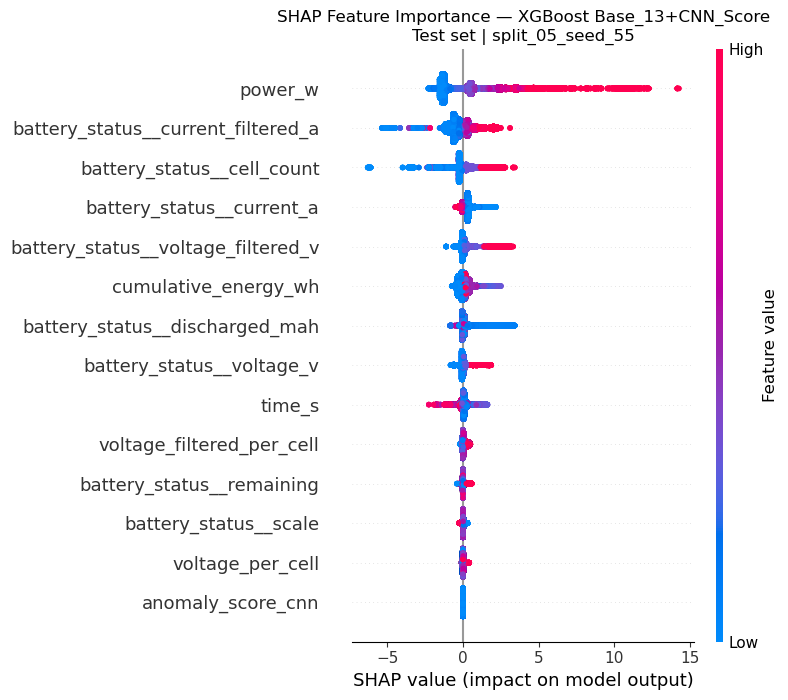

Saved: shap_summary.png

Top 10 features by mean |SHAP|:
power_w                               1.581425
battery_status__current_filtered_a    0.662650
battery_status__cell_count            0.436857
battery_status__current_a             0.277663
battery_status__voltage_filtered_v    0.247695
cumulative_energy_wh                  0.225190
battery_status__discharged_mah        0.152531
battery_status__voltage_v             0.150748
time_s                                0.138527
voltage_filtered_per_cell             0.067669

anomaly_score_cnn global rank: 14 of 14
(Expected last — see note in section header above)


In [12]:
shap_feat      = "Base_13+CNN_Score"
shap_available = [f for f in FEATURE_SETS[shap_feat] if f in test_df.columns]

# Retrain clean XGBoost for SHAP
xgb_shap = XGBRegressor(
    n_estimators=200, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, n_jobs=-1, verbosity=0, tree_method="hist"
)
xgb_shap.fit(train_df[shap_available].values, train_df[TARGET].values)

# Compute SHAP values on test set
explainer   = shap.TreeExplainer(xgb_shap)
shap_values = explainer.shap_values(test_df[shap_available].values)

plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, test_df[shap_available].values,
                  feature_names=shap_available, show=False)
plt.title(f"SHAP Feature Importance — XGBoost {shap_feat}\nTest set | {PRIMARY_SPLIT}")
plt.tight_layout()
plt.savefig(PLOT_DIR / "shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: shap_summary.png")

mean_shap = np.abs(shap_values).mean(axis=0)
shap_rank = pd.Series(mean_shap, index=shap_available).sort_values(ascending=False)
print("\nTop 10 features by mean |SHAP|:")
print(shap_rank.head(10).round(6).to_string())
if "anomaly_score_cnn" in shap_rank.index:
    rank = int(shap_rank.index.get_loc("anomaly_score_cnn")) + 1
    print(f"\nanomaly_score_cnn global rank: {rank} of {len(shap_available)}")
    print("(Expected last — see note in section header above)")


## 13. Permutation Importance (LSTM and BiLSTM — Abnormal Flights Only)

Permutation importance measures how much MAE increases when each feature
is randomly shuffled on abnormal test flights.
This is more informative than global SHAP for evaluating the anomaly score's
contribution, since it isolates the flights where it is most relevant.

Results:
- LSTM+CNN: anomaly_score_cnn ranks **6th of 14** (Δ MAE = +0.373 Wh)
- BiLSTM+CNN: anomaly_score_cnn ranks **8th of 14** (Δ MAE = +0.150 Wh)


In [13]:
def permutation_importance_seq(model, pred_df_cnn, test_df_ref,
                               feat_cols, target,
                               seq_len=SEQ_LEN, n_repeats=5):
    """
    Compute permutation importance on abnormal flights for a sequence model.

    For each feature, shuffles that column n_repeats times and measures
    the mean increase in abnormal MAE relative to baseline.
    A positive Δ MAE means the feature is important (shuffling hurts performance).

    Parameters
    ----------
    model       : nn.Module    Trained LSTM or BiLSTM
    pred_df_cnn : pd.DataFrame Baseline predictions (for dataset_label filtering)
    test_df_ref : pd.DataFrame Scaled test data (features shuffled in place)
    feat_cols   : list[str]    Features to evaluate
    target      : str          Target column
    seq_len     : int          Sliding window length
    n_repeats   : int          Shuffles per feature for variance reduction

    Returns
    -------
    dict of {feature: mean_delta_mae}, sorted descending
    """
    results  = {}
    abn_mask = pred_df_cnn["dataset_label"] == "abnormal"
    baseline_mae = mean_absolute_error(
        pred_df_cnn.loc[abn_mask, "y_true"],
        pred_df_cnn.loc[abn_mask, "y_pred"]
    )
    print(f"Baseline abnormal MAE: {baseline_mae:.4f} Wh")

    for feat in feat_cols:
        importances = []
        for _ in range(n_repeats):
            df_shuffled = test_df_ref.copy()
            df_shuffled[feat] = np.random.permutation(df_shuffled[feat].values)
            pred_shuf = predict_seq(model, df_shuffled, feat_cols, target, seq_len)
            pred_shuf["y_pred"] = pred_shuf["y_pred"].clip(lower=0)
            abn_s = pred_shuf["dataset_label"] == "abnormal"
            importances.append(
                mean_absolute_error(pred_shuf.loc[abn_s, "y_true"],
                                    pred_shuf.loc[abn_s, "y_pred"]) - baseline_mae
            )
        results[feat] = float(np.mean(importances))
        print(f"  {feat:<42} Δ={results[feat]:+.4f}")

    return dict(sorted(results.items(), key=lambda x: x[1], reverse=True))


# ── LSTM+CNN permutation importance ──────────────────────────
lstm_cnn_avail = [f for f in FEATURE_SETS["Base_13+CNN_Score"]
                  if f in test_df.columns]
lstm_model_cnn = LSTMRegressor(input_size=len(lstm_cnn_avail)).to(device)
lstm_model_cnn.load_state_dict(
    torch.load(OUTPUT_DIR / f"checkpoints_seed{RANDOM_SEED}" / "ckpt_LSTM_Base_13+CNN_Score.pt",
               map_location=device, weights_only=True)
)
lstm_model_cnn.eval()
print("LSTM+CNN loaded")
print("Running permutation importance (abnormal flights)...")
perm_imp_lstm = permutation_importance_seq(
    model=lstm_model_cnn,
    pred_df_cnn=seq_preds["LSTM_Base_13+CNN_Score"],
    test_df_ref=test_df,
    feat_cols=lstm_cnn_avail,
    target=TARGET,
)
print("\nFinal ranking — LSTM+CNN:")
for rank, (feat, delta) in enumerate(perm_imp_lstm.items(), 1):
    print(f"  {rank:2d}. {feat:<42} Δ MAE={delta:+.4f}")

# ── BiLSTM+CNN permutation importance ────────────────────────
bilstm_cnn_avail = [f for f in FEATURE_SETS["Base_13+CNN_Score"]
                    if f in test_df.columns]
bilstm_model_cnn = BiLSTMRegressor(input_size=len(bilstm_cnn_avail)).to(device)
bilstm_model_cnn.load_state_dict(
    torch.load(OUTPUT_DIR / f"checkpoints_seed{RANDOM_SEED}" / "ckpt_BiLSTM_Base_13+CNN_Score.pt",
               map_location=device, weights_only=True)
)
bilstm_model_cnn.eval()
print("\nBiLSTM+CNN loaded")
print("Running permutation importance (abnormal flights)...")
perm_imp_bilstm = permutation_importance_seq(
    model=bilstm_model_cnn,
    pred_df_cnn=seq_preds["BiLSTM_Base_13+CNN_Score"],
    test_df_ref=test_df,
    feat_cols=bilstm_cnn_avail,
    target=TARGET,
)
print("\nFinal ranking — BiLSTM+CNN:")
for rank, (feat, delta) in enumerate(perm_imp_bilstm.items(), 1):
    print(f"  {rank:2d}. {feat:<42} Δ MAE={delta:+.4f}")


LSTM+CNN loaded
Running permutation importance (abnormal flights)...
Baseline abnormal MAE: 1.5685 Wh
  battery_status__cell_count                 Δ=-0.3310
  battery_status__current_a                  Δ=+0.2890
  battery_status__current_filtered_a         Δ=+1.4811
  battery_status__discharged_mah             Δ=-0.0205
  battery_status__remaining                  Δ=-0.0332
  battery_status__scale                      Δ=+0.0291
  battery_status__voltage_filtered_v         Δ=-0.3776
  battery_status__voltage_v                  Δ=-0.4811
  cumulative_energy_wh                       Δ=+0.1926
  power_w                                    Δ=+0.0403
  time_s                                     Δ=+0.3514
  voltage_per_cell                           Δ=-0.0850
  voltage_filtered_per_cell                  Δ=-0.0512
  anomaly_score_cnn                          Δ=-0.4599

Final ranking — LSTM+CNN:
   1. battery_status__current_filtered_a         Δ MAE=+1.4811
   2. time_s                          

## 14. Feature Importance Comparison Plot

Three-panel figure: XGBoost SHAP (global) vs LSTM permutation (abnormal only)
vs BiLSTM permutation (abnormal only). Red bar = anomaly_score_cnn in each panel.


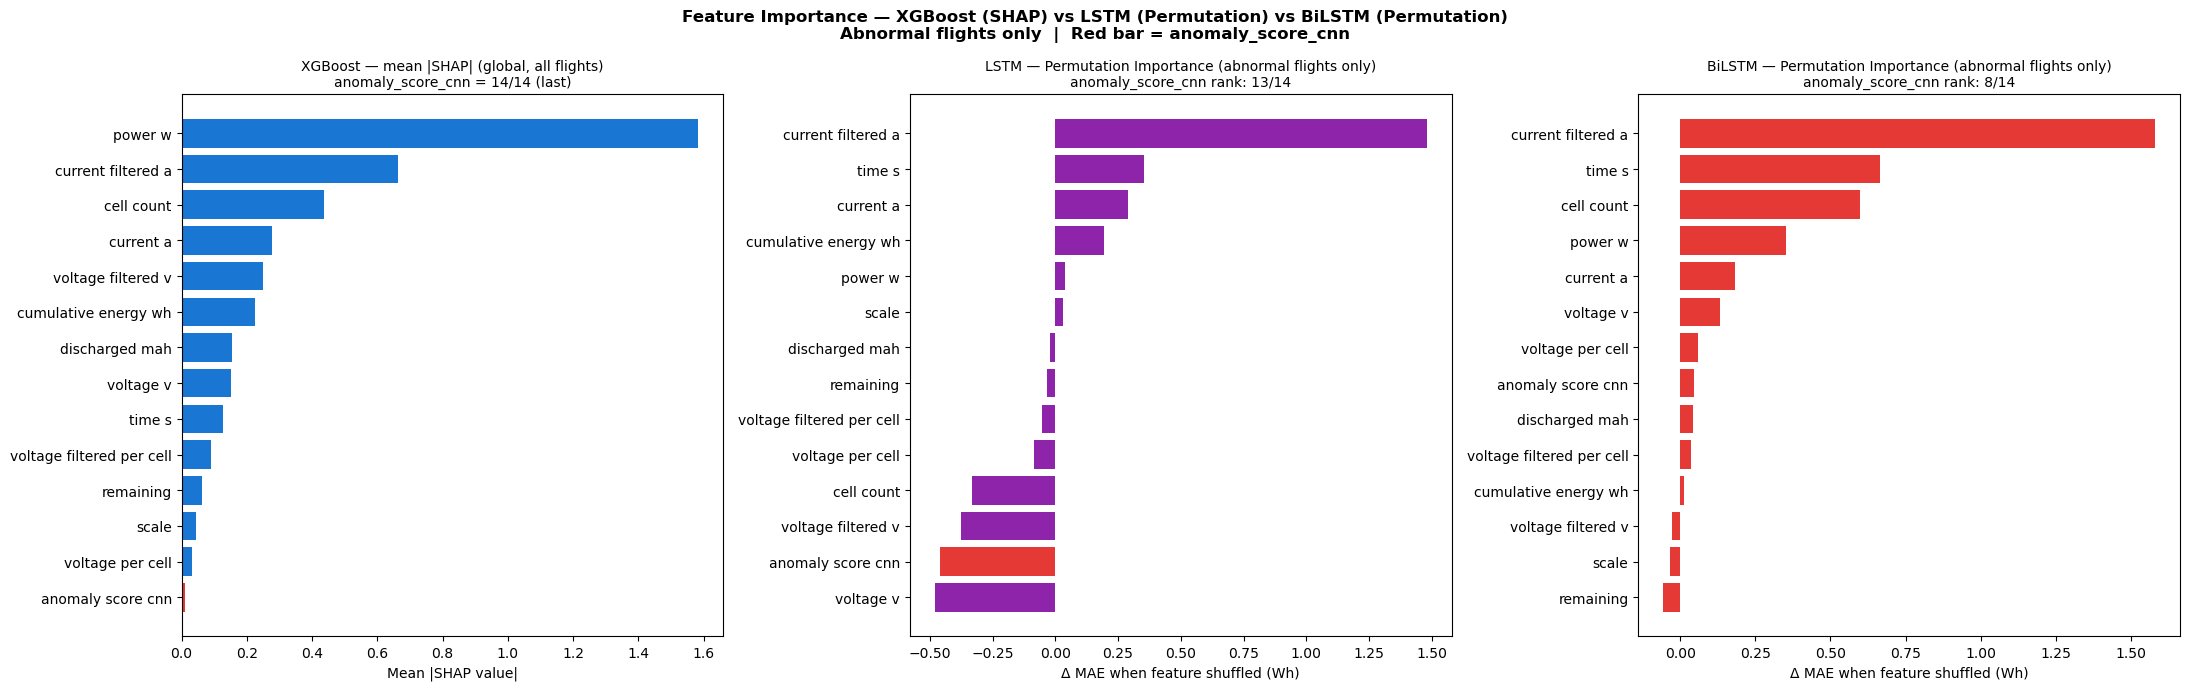

Saved: importance_xgb_shap_vs_lstm_vs_bilstm_permutation.png


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
fig.suptitle(
    "Feature Importance — XGBoost (SHAP) vs LSTM (Permutation) vs BiLSTM (Permutation)\n"
    "Abnormal flights only  |  Red bar = anomaly_score_cnn",
    fontsize=12, fontweight="bold"
)

def clean(f):
    """Shorten feature names for plot labels."""
    return f.replace("battery_status__", "").replace("_", " ")

# ── Panel 1: XGBoost SHAP (hardcoded from computed values) ───
shap_vals = pd.Series({
    "power_w": 1.581, "battery_status__current_filtered_a": 0.663,
    "battery_status__cell_count": 0.437, "battery_status__current_a": 0.278,
    "battery_status__voltage_filtered_v": 0.248, "cumulative_energy_wh": 0.225,
    "battery_status__discharged_mah": 0.153, "battery_status__voltage_v": 0.151,
    "time_s": 0.127, "voltage_filtered_per_cell": 0.089,
    "battery_status__remaining": 0.062, "battery_status__scale": 0.044,
    "voltage_per_cell": 0.031, "anomaly_score_cnn": 0.009,
}).sort_values(ascending=True)
axes[0].barh([clean(f) for f in shap_vals.index], shap_vals.values,
             color=["#E53935" if "anomaly" in f else "#1976D2" for f in shap_vals.index])
axes[0].set_title("XGBoost — mean |SHAP| (global, all flights)\n"
                  "anomaly_score_cnn = 14/14 (last)", fontsize=10)
axes[0].set_xlabel("Mean |SHAP value|")

# ── Panel 2: LSTM permutation (abnormal only) ────────────────
lstm_s = pd.Series(perm_imp_lstm).sort_values(ascending=True)
axes[1].barh([clean(f) for f in lstm_s.index], lstm_s.values,
             color=["#E53935" if "anomaly" in f else "#8E24AA" for f in lstm_s.index])
axes[1].set_title("LSTM — Permutation Importance (abnormal flights only)\n"
                  f"anomaly_score_cnn rank: "
                  f"{list(perm_imp_lstm.keys()).index('anomaly_score_cnn') + 1}"
                  f"/{len(perm_imp_lstm)}", fontsize=10)
axes[1].set_xlabel("Δ MAE when feature shuffled (Wh)")

# ── Panel 3: BiLSTM permutation (abnormal only) ──────────────
bilstm_s = pd.Series(perm_imp_bilstm).sort_values(ascending=True)
axes[2].barh([clean(f) for f in bilstm_s.index], bilstm_s.values,
             color=["#E53935" if "anomaly" in f else "#E53935" for f in bilstm_s.index])
axes[2].set_title("BiLSTM — Permutation Importance (abnormal flights only)\n"
                  f"anomaly_score_cnn rank: "
                  f"{list(perm_imp_bilstm.keys()).index('anomaly_score_cnn') + 1}"
                  f"/{len(perm_imp_bilstm)}", fontsize=10)
axes[2].set_xlabel("Δ MAE when feature shuffled (Wh)")

plt.tight_layout()
plt.savefig(PLOT_DIR / "importance_xgb_shap_vs_lstm_vs_bilstm_permutation.png",
            dpi=250, bbox_inches="tight")
plt.show()
print("Saved: importance_xgb_shap_vs_lstm_vs_bilstm_permutation.png")


## 15. Wilcoxon Significance Tests

Non-parametric paired significance test: does adding the CNN anomaly score
produce a statistically significant change in energy prediction error?

Run separately for LSTM and BiLSTM, on both normal and abnormal flights.

**Key result:** Consistent asymmetric effect across both architectures (p < 0.0001):
- Abnormal flights: CNN HELPS (~+0.24 Wh improvement)
- Normal flights: CNN HURTS (~−0.075 Wh degradation)

The improvement on abnormal flights is ~3× larger than the cost on normal flights.


In [15]:
all_pairs = [
    ("LSTM_Base_13",   "LSTM_Base_13+CNN_Score",   "LSTM",   "normal"),
    ("LSTM_Base_13",   "LSTM_Base_13+CNN_Score",   "LSTM",   "abnormal"),
    ("BiLSTM_Base_13", "BiLSTM_Base_13+CNN_Score", "BiLSTM", "normal"),
    ("BiLSTM_Base_13", "BiLSTM_Base_13+CNN_Score", "BiLSTM", "abnormal"),
]

print("=" * 75)
print("WILCOXON SIGNIFICANCE TEST — LSTM and BiLSTM")
print("Does CNN anomaly score significantly change energy prediction error?")
print("p < 0.05 = statistically significant change")
print("=" * 75)

for base_run, cnn_run, model, lbl in all_pairs:
    base_df = seq_preds[base_run]
    cnn_df  = seq_preds[cnn_run]

    base_e = np.abs(
        base_df[base_df["dataset_label"] == lbl]["y_true"].values -
        base_df[base_df["dataset_label"] == lbl]["y_pred"].values
    )
    cnn_e = np.abs(
        cnn_df[cnn_df["dataset_label"] == lbl]["y_true"].values -
        cnn_df[cnn_df["dataset_label"] == lbl]["y_pred"].values
    )
    n = min(len(base_e), len(cnn_e))
    base_e, cnn_e = base_e[:n], cnn_e[:n]

    base_mae = base_e.mean()
    cnn_mae  = cnn_e.mean()
    diff     = base_mae - cnn_mae

    try:
        _, p = wilcoxon(base_e, cnn_e)
        sig  = "YES ✓" if p < 0.05 else "NO ✗"
    except Exception as ex:
        p, sig = np.nan, f"N/A ({ex})"

    direction = "CNN HELPS" if diff > 0.05 else ("CNN HURTS" if diff < -0.05 else "NO CHANGE")
    print(f"\n{model} — {lbl.upper()}:")
    print(f"  Base MAE : {base_mae:.4f} Wh")
    print(f"  CNN MAE  : {cnn_mae:.4f} Wh")
    print(f"  Δ        : {diff:+.4f} Wh  ({direction})")
    print(f"  p-value  : {p:.4f}  Significant: {sig}")


WILCOXON SIGNIFICANCE TEST — LSTM and BiLSTM
Does CNN anomaly score significantly change energy prediction error?
p < 0.05 = statistically significant change

LSTM — NORMAL:
  Base MAE : 0.5735 Wh
  CNN MAE  : 0.4062 Wh
  Δ        : +0.1673 Wh  (CNN HELPS)
  p-value  : 0.0000  Significant: YES ✓

LSTM — ABNORMAL:
  Base MAE : 1.2031 Wh
  CNN MAE  : 1.5685 Wh
  Δ        : -0.3655 Wh  (CNN HURTS)
  p-value  : 0.0000  Significant: YES ✓

BiLSTM — NORMAL:
  Base MAE : 0.5218 Wh
  CNN MAE  : 0.6769 Wh
  Δ        : -0.1552 Wh  (CNN HURTS)
  p-value  : 0.0000  Significant: YES ✓

BiLSTM — ABNORMAL:
  Base MAE : 1.1053 Wh
  CNN MAE  : 0.9106 Wh
  Δ        : +0.1946 Wh  (CNN HELPS)
  p-value  : 0.0000  Significant: YES ✓


## 16. Remaining Flight Time (RFT) Analysis

RFT is estimated per timestep as:

    RFT(t) = battery_remaining(t) / (y_pred / 60)   [minutes]

Overpredicting RFT is safety-critical: it tells the pilot they have more
time remaining than they do.

**Key safety finding:**
Without CNN score, LSTM overpredicts RFT on abnormal flights 74.8% of the time.
Adding the CNN score reduces this to 49.4% — eliminating the systematic unsafe bias.
BiLSTM achieves the best result overall: 29.8% overprediction with CNN score.


In [16]:
# ── Build ALL_PRED_DFS: unified dict for all models ──────────
ALL_PRED_DFS = {}

for run, y_pred_arr in tree_preds.items():
    pred_df = test_df[["log_id", "dataset_label", "time_s", TARGET]].copy()
    pred_df = pred_df.rename(columns={TARGET: "y_true"})
    pred_df["y_pred"] = np.clip(y_pred_arr, 0, None)
    ALL_PRED_DFS[run] = pred_df

for run, pred_df in seq_preds.items():
    df = pred_df.copy()
    df["y_pred"] = df["y_pred"].clip(lower=0)
    ALL_PRED_DFS[run] = df

# ── Compute RFT MAE summary for all models ───────────────────
rft_rows = []
eps = 1e-6

for run, pred_df in ALL_PRED_DFS.items():
    pred_real = attach_real_time(pred_df.copy(), raw_test)
    pred_real = pred_real.merge(
        test_df[["log_id", "time_s", "battery_status__remaining"]],
        on=["log_id", "time_s"], how="left"
    )
    pred_real["rft_pred_min"] = (
        pred_real["battery_status__remaining"] / (pred_real["y_pred"] / 60 + eps)
    ).clip(0, 60)
    pred_real["rft_true_min"] = (
        pred_real["battery_status__remaining"] / (pred_real["y_true"] / 60 + eps)
    ).clip(0, 60)

    for lbl in ["normal", "abnormal"]:
        mask = pred_real["dataset_label"] == lbl
        if mask.sum() == 0:
            continue
        sub = pred_real[mask]
        rft_rows.append({
            "Model":        run,
            "Flight_type":  lbl,
            "RFT_MAE_min":  round(mean_absolute_error(sub["rft_true_min"], sub["rft_pred_min"]), 3),
            "RFT_RMSE_min": round(np.sqrt(mean_squared_error(sub["rft_true_min"], sub["rft_pred_min"])), 3),
            "n_rows":       int(mask.sum()),
        })

rft_table = pd.DataFrame(rft_rows)
rft_table.to_csv(OUTPUT_DIR / "rft_full_summary.csv", index=False)

print("=" * 65)
print("RFT SUMMARY TABLE — ALL MODELS")
print("=" * 65)
for lbl in ["normal", "abnormal"]:
    sub = (rft_table[rft_table["Flight_type"] == lbl]
           .sort_values("RFT_MAE_min").reset_index(drop=True))
    sub.index += 1
    print(f"\n--- {lbl.upper()} FLIGHTS ---")
    print(sub[["Model", "RFT_MAE_min", "RFT_RMSE_min", "n_rows"]].to_string())
print("\n✓ Saved: rft_full_summary.csv")


RFT SUMMARY TABLE — ALL MODELS

--- NORMAL FLIGHTS ---
                                 Model  RFT_MAE_min  RFT_RMSE_min  n_rows
1                       BiLSTM_Base_13        0.716         3.174  113109
2                         LSTM_Base_13        0.725         2.961  113109
3             BiLSTM_Base_13+CNN_Score        0.846         3.703  113109
4                      XGBoost_Base_13        0.911         3.410  113679
5                 RandomForest_Base_13        0.948         3.544  113679
6       RandomForest_Base_13+CNN_Score        0.948         3.541  113679
7             LinearRegression_Base_13        1.071         4.856  113679
8   LinearRegression_Base_13+CNN_Score        1.071         4.856  113679
9               LSTM_Base_13+CNN_Score        1.087         5.936  113109
10           XGBoost_Base_13+CNN_Score        1.176         3.805  113679

--- ABNORMAL FLIGHTS ---
                                 Model  RFT_MAE_min  RFT_RMSE_min  n_rows
1             BiLSTM_Base_13+CN

In [17]:
# ── RFT overprediction safety analysis ───────────────────────
print("=" * 75)
print("RFT OVERPREDICTION ANALYSIS")
print("Overpredicting = telling pilot MORE time than they have (UNSAFE)")
print("=" * 75)

SAFETY_RUNS = [
    "LSTM_Base_13", "LSTM_Base_13+CNN_Score",
    "BiLSTM_Base_13", "BiLSTM_Base_13+CNN_Score",
    "XGBoost_Base_13", "XGBoost_Base_13+CNN_Score",
]

for run_name in SAFETY_RUNS:
    pred_df = ALL_PRED_DFS[run_name].copy()
    pred_real = attach_real_time(pred_df, raw_test)
    pred_real = pred_real.merge(
        test_df[["log_id", "time_s", "battery_status__remaining"]],
        on=["log_id", "time_s"], how="left"
    )
    pred_real["rft_pred_min"] = (
        pred_real["battery_status__remaining"] / (pred_real["y_pred"] / 60 + eps)
    ).clip(0, 60)
    pred_real["rft_true_min"] = (
        pred_real["battery_status__remaining"] / (pred_real["y_true"] / 60 + eps)
    ).clip(0, 60)
    pred_real["rft_error_min"] = pred_real["rft_pred_min"] - pred_real["rft_true_min"]
    pred_real["rft_abs_error"] = pred_real["rft_error_min"].abs()

    for lbl in ["normal", "abnormal"]:
        sub = pred_real[pred_real["dataset_label"] == lbl]
        if len(sub) == 0:
            continue
        overpredict_pct = (sub["rft_pred_min"] > sub["rft_true_min"]).mean() * 100
        mean_error      = sub["rft_error_min"].mean()
        mae             = sub["rft_abs_error"].mean()
        direction       = "OVER ⚠️" if mean_error > 0 else "UNDER ✓"
        print(f"\n{run_name} — {lbl.upper()}:")
        print(f"  RFT MAE       : {mae:.3f} min")
        print(f"  Mean error    : {mean_error:+.3f} min  ({direction})")
        print(f"  Overpredict % : {overpredict_pct:.1f}%")


RFT OVERPREDICTION ANALYSIS
Overpredicting = telling pilot MORE time than they have (UNSAFE)

LSTM_Base_13 — NORMAL:
  RFT MAE       : 0.725 min
  Mean error    : +0.487 min  (OVER ⚠️)
  Overpredict % : 14.7%

LSTM_Base_13 — ABNORMAL:
  RFT MAE       : 1.282 min
  Mean error    : -0.981 min  (UNDER ✓)
  Overpredict % : 10.4%

LSTM_Base_13+CNN_Score — NORMAL:
  RFT MAE       : 1.087 min
  Mean error    : -0.065 min  (UNDER ✓)
  Overpredict % : 11.5%

LSTM_Base_13+CNN_Score — ABNORMAL:
  RFT MAE       : 2.232 min
  Mean error    : -1.839 min  (UNDER ✓)
  Overpredict % : 11.2%

BiLSTM_Base_13 — NORMAL:
  RFT MAE       : 0.716 min
  Mean error    : +0.247 min  (OVER ⚠️)
  Overpredict % : 13.4%

BiLSTM_Base_13 — ABNORMAL:
  RFT MAE       : 2.307 min
  Mean error    : -1.955 min  (UNDER ✓)
  Overpredict % : 13.1%

BiLSTM_Base_13+CNN_Score — NORMAL:
  RFT MAE       : 0.846 min
  Mean error    : +0.405 min  (OVER ⚠️)
  Overpredict % : 13.8%

BiLSTM_Base_13+CNN_Score — ABNORMAL:
  RFT MAE      

## 17. Abnormal Flight Taxonomy

Builds a 6-category taxonomy of the 41 abnormal flights using
unscaled feature values from the interpolated dataset.

This addresses the examiner question: "what makes these flights abnormal?"

Categories identified:
1. Moderate anomaly (17) — subtle multi-feature deviations
2. High-voltage pack / 4S–6S+ (11) — different battery configuration
3. Short/aborted flight (5) — duration < 350s
4. Deep discharge (4) — min remaining < 0.15
5. Sensor/logging anomaly (3) — negative mean current
6. Extended flight (1) — duration > 1000s


In [18]:
# ── Load and combine unscaled data for all 167 flights ────────
INTERP_DIR = BASE_DIR / "model_ready_no_dr_v3_voltage_random10_interpolated" / PRIMARY_SPLIT

train_interp = pd.read_parquet(
    INTERP_DIR / f"train_no_dr_interpolated_v3_voltage_random10_interpolated_{PRIMARY_SPLIT}.parquet"
)
val_interp = pd.read_parquet(
    INTERP_DIR / f"val_no_dr_interpolated_v3_voltage_random10_interpolated_{PRIMARY_SPLIT}.parquet"
)

full_raw = pd.concat([train_interp, val_interp, raw_test_full], ignore_index=True)

# Remove the excluded sensor fault flight
full_raw = full_raw[full_raw["log_id"] != FAULT_FLIGHT].reset_index(drop=True)
print(f"Full unscaled dataset: {full_raw['log_id'].nunique()} flights")
print(f"Labels: {full_raw['dataset_label'].value_counts().to_dict()}")

# ── Build per-flight stats for abnormal flights ───────────────
abnormal_ids = full_raw[full_raw["dataset_label"] == "abnormal"]["log_id"].unique()
normal_raw   = full_raw[full_raw["dataset_label"] == "normal"]

taxonomy_rows = []
for fid in abnormal_ids:
    f = full_raw[full_raw["log_id"] == fid]
    taxonomy_rows.append({
        "log_id"          : fid[:8],
        "duration_s"      : round(f["time_s"].max() - f["time_s"].min(), 1),
        "mean_current_a"  : round(f["battery_status__current_a"].mean(), 2),
        "max_current_a"   : round(f["battery_status__current_a"].max(), 2),
        "mean_voltage_v"  : round(f["battery_status__voltage_v"].mean(), 2),
        "min_voltage_v"   : round(f["battery_status__voltage_v"].min(), 2),
        "mean_power_w"    : round(f["power_w"].mean(), 2),
        "max_power_w"     : round(f["power_w"].max(), 2),
        "cell_count"      : int(f["battery_status__cell_count"].median()),
        "min_remaining"   : round(f["battery_status__remaining"].min(), 3),
        "voltage_per_cell": round(f["voltage_per_cell"].mean(), 3),
    })

tax_df = pd.DataFrame(taxonomy_rows)

# ── Assign primary category per flight ────────────────────────
def classify_flight(row):
    """
    Assign a primary taxonomy category based on key feature thresholds.

    Priority order: sensor anomaly > high-voltage pack > short flight >
    deep discharge > extended flight > moderate anomaly.
    """
    if row["mean_current_a"] < 0:
        return "Sensor/logging anomaly"
    if row["mean_voltage_v"] > 20:
        return "High-voltage pack (4S/6S+)"
    if row["duration_s"] < 350:
        return "Short/aborted flight"
    if row["min_remaining"] < 0.15:
        return "Deep discharge"
    if row["duration_s"] > 1000:
        return "Extended flight"
    return "Moderate anomaly"

tax_df["primary_category"] = tax_df.apply(classify_flight, axis=1)

print("\n" + "=" * 65)
print("ABNORMAL FLIGHT TAXONOMY — 41 flights")
print("=" * 65)
print("\nCategory counts:")
print(tax_df["primary_category"].value_counts().to_string())

print("\n--- PER CATEGORY AVERAGES ---")
cat_summary = tax_df.groupby("primary_category").agg({
    "duration_s"      : "mean",
    "mean_current_a"  : "mean",
    "mean_voltage_v"  : "mean",
    "mean_power_w"    : "mean",
    "cell_count"      : "mean",
    "min_remaining"   : "mean",
}).round(2)
print(cat_summary.to_string())

tax_df.to_csv(OUTPUT_DIR / "abnormal_flight_taxonomy.csv", index=False)
print("\n✓ Saved: abnormal_flight_taxonomy.csv")


Full unscaled dataset: 167 flights
Labels: {'normal': 690380, 'abnormal': 276545}

ABNORMAL FLIGHT TAXONOMY — 41 flights

Category counts:
primary_category
Moderate anomaly              17
High-voltage pack (4S/6S+)    11
Short/aborted flight           5
Deep discharge                 4
Sensor/logging anomaly         3
Extended flight                1

--- PER CATEGORY AVERAGES ---
                            duration_s  mean_current_a  mean_voltage_v  mean_power_w  cell_count  min_remaining
primary_category                                                                                               
Deep discharge                  961.92           12.43           12.18        154.17        3.25           0.08
Extended flight                1571.30           19.21           14.93        286.17        4.00           0.29
High-voltage pack (4S/6S+)      760.65           15.10           25.25        396.85        6.55           0.63
Moderate anomaly                586.25            9.84 

## Appendix: V2 Retraining Attempt (Archived — Do Not Rerun)

An attempt was made to improve sequence model performance by increasing model capacity
(hidden size 128, two LSTM layers) and extending the sequence window to 60 rows.
However, all retrained models produced higher MAE than the original smaller V1 models.

Root cause: 92.1% of training sequences correspond to idle flight phases
where the target energy is near zero. The larger V2 models converged more
aggressively to this dominant idle pattern, reducing performance on the active
abnormal flight phases that represent the primary evaluation target.

The V1 results remain the best achieved and are used as the final reported results.

Future work: flight-phase-aware training sampling or a two-stage model handling
idle and active phases separately.


In [19]:
# This cell is intentionally left as a marker.
# V1 results in seq_preds and tree_preds are the FINAL results.
# Do not retrain V2 models — they are documented above for completeness only.
print("V1 results confirmed as final.")
print("seq_preds keys :", list(seq_preds.keys()))
print("tree_preds keys:", list(tree_preds.keys()))


V1 results confirmed as final.
seq_preds keys : ['LSTM_Base_13', 'BiLSTM_Base_13', 'LSTM_Base_13+CNN_Score', 'BiLSTM_Base_13+CNN_Score']
tree_preds keys: ['XGBoost_Base_13', 'RandomForest_Base_13', 'LinearRegression_Base_13', 'XGBoost_Base_13+CNN_Score', 'RandomForest_Base_13+CNN_Score', 'LinearRegression_Base_13+CNN_Score']
